In [ ]:
pip install numpy pandas matplotlib scikit-learn scipy shap joblib openpyxl

In [30]:
# ======================================================================
# PART 1
# MODEL BENCHMARKING FRAMEWORK
# (Random Forest, XGBoost, LightGBM, CatBoost, LSTM)
# ======================================================================

print("="*70)
print("PART 1 : DATA PREPARATION")
print("="*70)

# ======================================================================
# INSTALL (Run only once if needed)
# ======================================================================

# pip install numpy pandas matplotlib scikit-learn
# pip install xgboost lightgbm catboost shap
# pip install tensorflow

# ======================================================================
# IMPORT LIBRARIES
# ======================================================================

import warnings
warnings.filterwarnings("ignore")

import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ======================================================================
# REPRODUCIBILITY
# ======================================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# ======================================================================
# READ DATASET
# ======================================================================

print("\nReading Dataset...")

ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output"

input_csv = os.path.join(
    ml_dir,
    "lagged_ml_ready.csv"
)

df = pd.read_csv(input_csv)

print(f"Dataset Shape : {df.shape}")

# ======================================================================
# DEFINE FEATURES
# ======================================================================

drop_columns = [
    "VCI",
    "Row_Idx",
    "Col_Idx",
    "Year"
]

X = df.drop(columns=drop_columns)

y = df["VCI"].copy()

print(f"\nTotal Features : {X.shape[1]}")

# ======================================================================
# NORMALIZE TARGET VARIABLE (VCI)
# ======================================================================

print("\nNormalizing VCI to [0,1]...")

target_scaler = MinMaxScaler()

y = target_scaler.fit_transform(
    y.values.reshape(-1,1)
).ravel()

print(f"VCI Minimum : {y.min():.3f}")
print(f"VCI Maximum : {y.max():.3f}")

# ======================================================================
# TRAIN / TEST SPLIT (70% Train, 30% Test)
# ======================================================================

print("\nCreating Train/Test Split (70/30)...")

# Changed fixed sample counts (100000/30000) to percentage based split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,      # Allocates 30% for testing (automatically makes train 70%)
    random_state=42,     # Ensures reproducible randomness
    shuffle=True         # Shuffles the data randomly before splitting
)

print("\nTraining Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

# ======================================================================
# COMMON EVALUATION FUNCTION
# ======================================================================

def evaluate_model(model, X_train, X_test, y_train, y_test):

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2  = r2_score(y_test, test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae  = mean_absolute_error(y_test, test_pred)

    return {
        "train_r2":train_r2,
        "test_r2":test_r2,
        "train_rmse":train_rmse,
        "test_rmse":test_rmse,
        "train_mae":train_mae,
        "test_mae":test_mae,
        "train_pred":train_pred,
        "test_pred":test_pred
    }

# ======================================================================
# FIGURE SETTINGS
# ======================================================================

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

print("\nData preparation completed successfully.")
print("="*70)
print("Proceed to Part 2 (Random Forest)")
print("="*70)

PART 1 : DATA PREPARATION

Reading Dataset...
Dataset Shape : (943957, 24)

Total Features : 20

Normalizing VCI to [0,1]...
VCI Minimum : 0.000
VCI Maximum : 1.000

Creating Train/Test Split (70/30)...

Training Samples : 660769
Testing Samples  : 283188

Data preparation completed successfully.
Proceed to Part 2 (Random Forest)


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

# ======================================================================
# Assume X and y are already defined above
# ======================================================================

# ======================================================================
# 1. DATA SPLIT (70% Train, 30% Test)
# ======================================================================
print("Creating Train/Test Split (70/30)...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, shuffle=True
)

# ======================================================================
# 2. INITIALIZE AND TRAIN MODEL
# ======================================================================
print("Training XGBoost...")
xgb_model = XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=15,
    min_child_weight=7,
    subsample=0.75,
    colsample_bytree=0.75,
    gamma=0.01,
    reg_alpha=0.8,
    reg_lambda=2.0,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    eval_metric='rmse'
)

xgb_model.fit(X_train, y_train)
print("Training Completed.")

# ======================================================================
# 3. EVALUATE MODEL (Fixed - Return Predictions Too)
# ======================================================================
def evaluate_model(model, X_train, X_test, y_train, y_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    return {
        "train_r2": r2_score(y_train, train_pred),
        "test_r2": r2_score(y_test, test_pred),
        "train_rmse": np.sqrt(mean_squared_error(y_train, train_pred)),
        "test_rmse": np.sqrt(mean_squared_error(y_test, test_pred)),
        "train_mae": mean_absolute_error(y_train, train_pred),
        "test_mae": mean_absolute_error(y_test, test_pred),
        "train_pred": train_pred,      # ← Added
        "test_pred": test_pred         # ← Added
    }

results = evaluate_model(xgb_model, X_train, X_test, y_train, y_test)

# Print Performance
print("\n" + "="*70)
print("TRAINING PERFORMANCE")
print("="*70)
print(f"R² Score : {results['train_r2']:.4f}")
print(f"RMSE     : {results['train_rmse']:.4f}")
print(f"MAE      : {results['train_mae']:.4f}")

print("\n" + "="*70)
print("TESTING PERFORMANCE")
print("="*70)
print(f"R² Score : {results['test_r2']:.4f}")
print(f"RMSE     : {results['test_rmse']:.4f}")
print(f"MAE      : {results['test_mae']:.4f}")
print("="*70)

# ======================================================================
# 4. HIGH-RESOLUTION JOURNAL SCATTERPLOTS
# ======================================================================
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

fig = plt.figure(figsize=(12, 5), facecolor='white')
box_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='lightgray')

# --- Training Scatter Plot ---
ax1 = plt.subplot(1, 2, 1, facecolor='white')
plt.scatter(y_train, results['train_pred'], alpha=0.15, color='tab:cyan', s=1)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)

train_text = f"R²: {results['train_r2']:.4f}\nRMSE: {results['train_rmse']:.4f}\nMAE: {results['train_mae']:.4f}"
ax1.text(0.05, 0.95, train_text, transform=ax1.transAxes, fontsize=10,
         verticalalignment='top', bbox=box_props)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('Actual VCI')
plt.ylabel('Predicted VCI')
plt.title('Training: Actual vs Predicted')
plt.grid(True, linestyle=':', alpha=0.4, color='gray')

# --- Testing Scatter Plot ---
ax2 = plt.subplot(1, 2, 2, facecolor='white')
plt.scatter(y_test, results['test_pred'], alpha=0.2, color='tab:cyan', s=1)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)

test_text = f"R²: {results['test_r2']:.4f}\nRMSE: {results['test_rmse']:.4f}\nMAE: {results['test_mae']:.4f}"
ax2.text(0.05, 0.95, test_text, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', bbox=box_props)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('Actual VCI')
plt.ylabel('Predicted VCI')
plt.title('Test: Actual vs Predicted')
plt.grid(True, linestyle=':', alpha=0.4, color='gray')

plt.tight_layout()
plt.savefig("XGBoost_Journal_Scatter.png", dpi=300, bbox_inches='tight')
plt.show()

Plots will be saved to: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\shap analysis

Reading Dataset...
Dataset Shape: (943957, 24)
Training Samples: 660769
Testing Samples : 283188

Training XGBoost...
Training Completed.

MODEL PERFORMANCE SUMMARY
Train R²   : 0.9586
Test  R²   : 0.8871
Train RMSE : 0.0549
Test  RMSE : 0.0907
Train MAE  : 0.0402
Test  MAE  : 0.0634

Computing SHAP values...


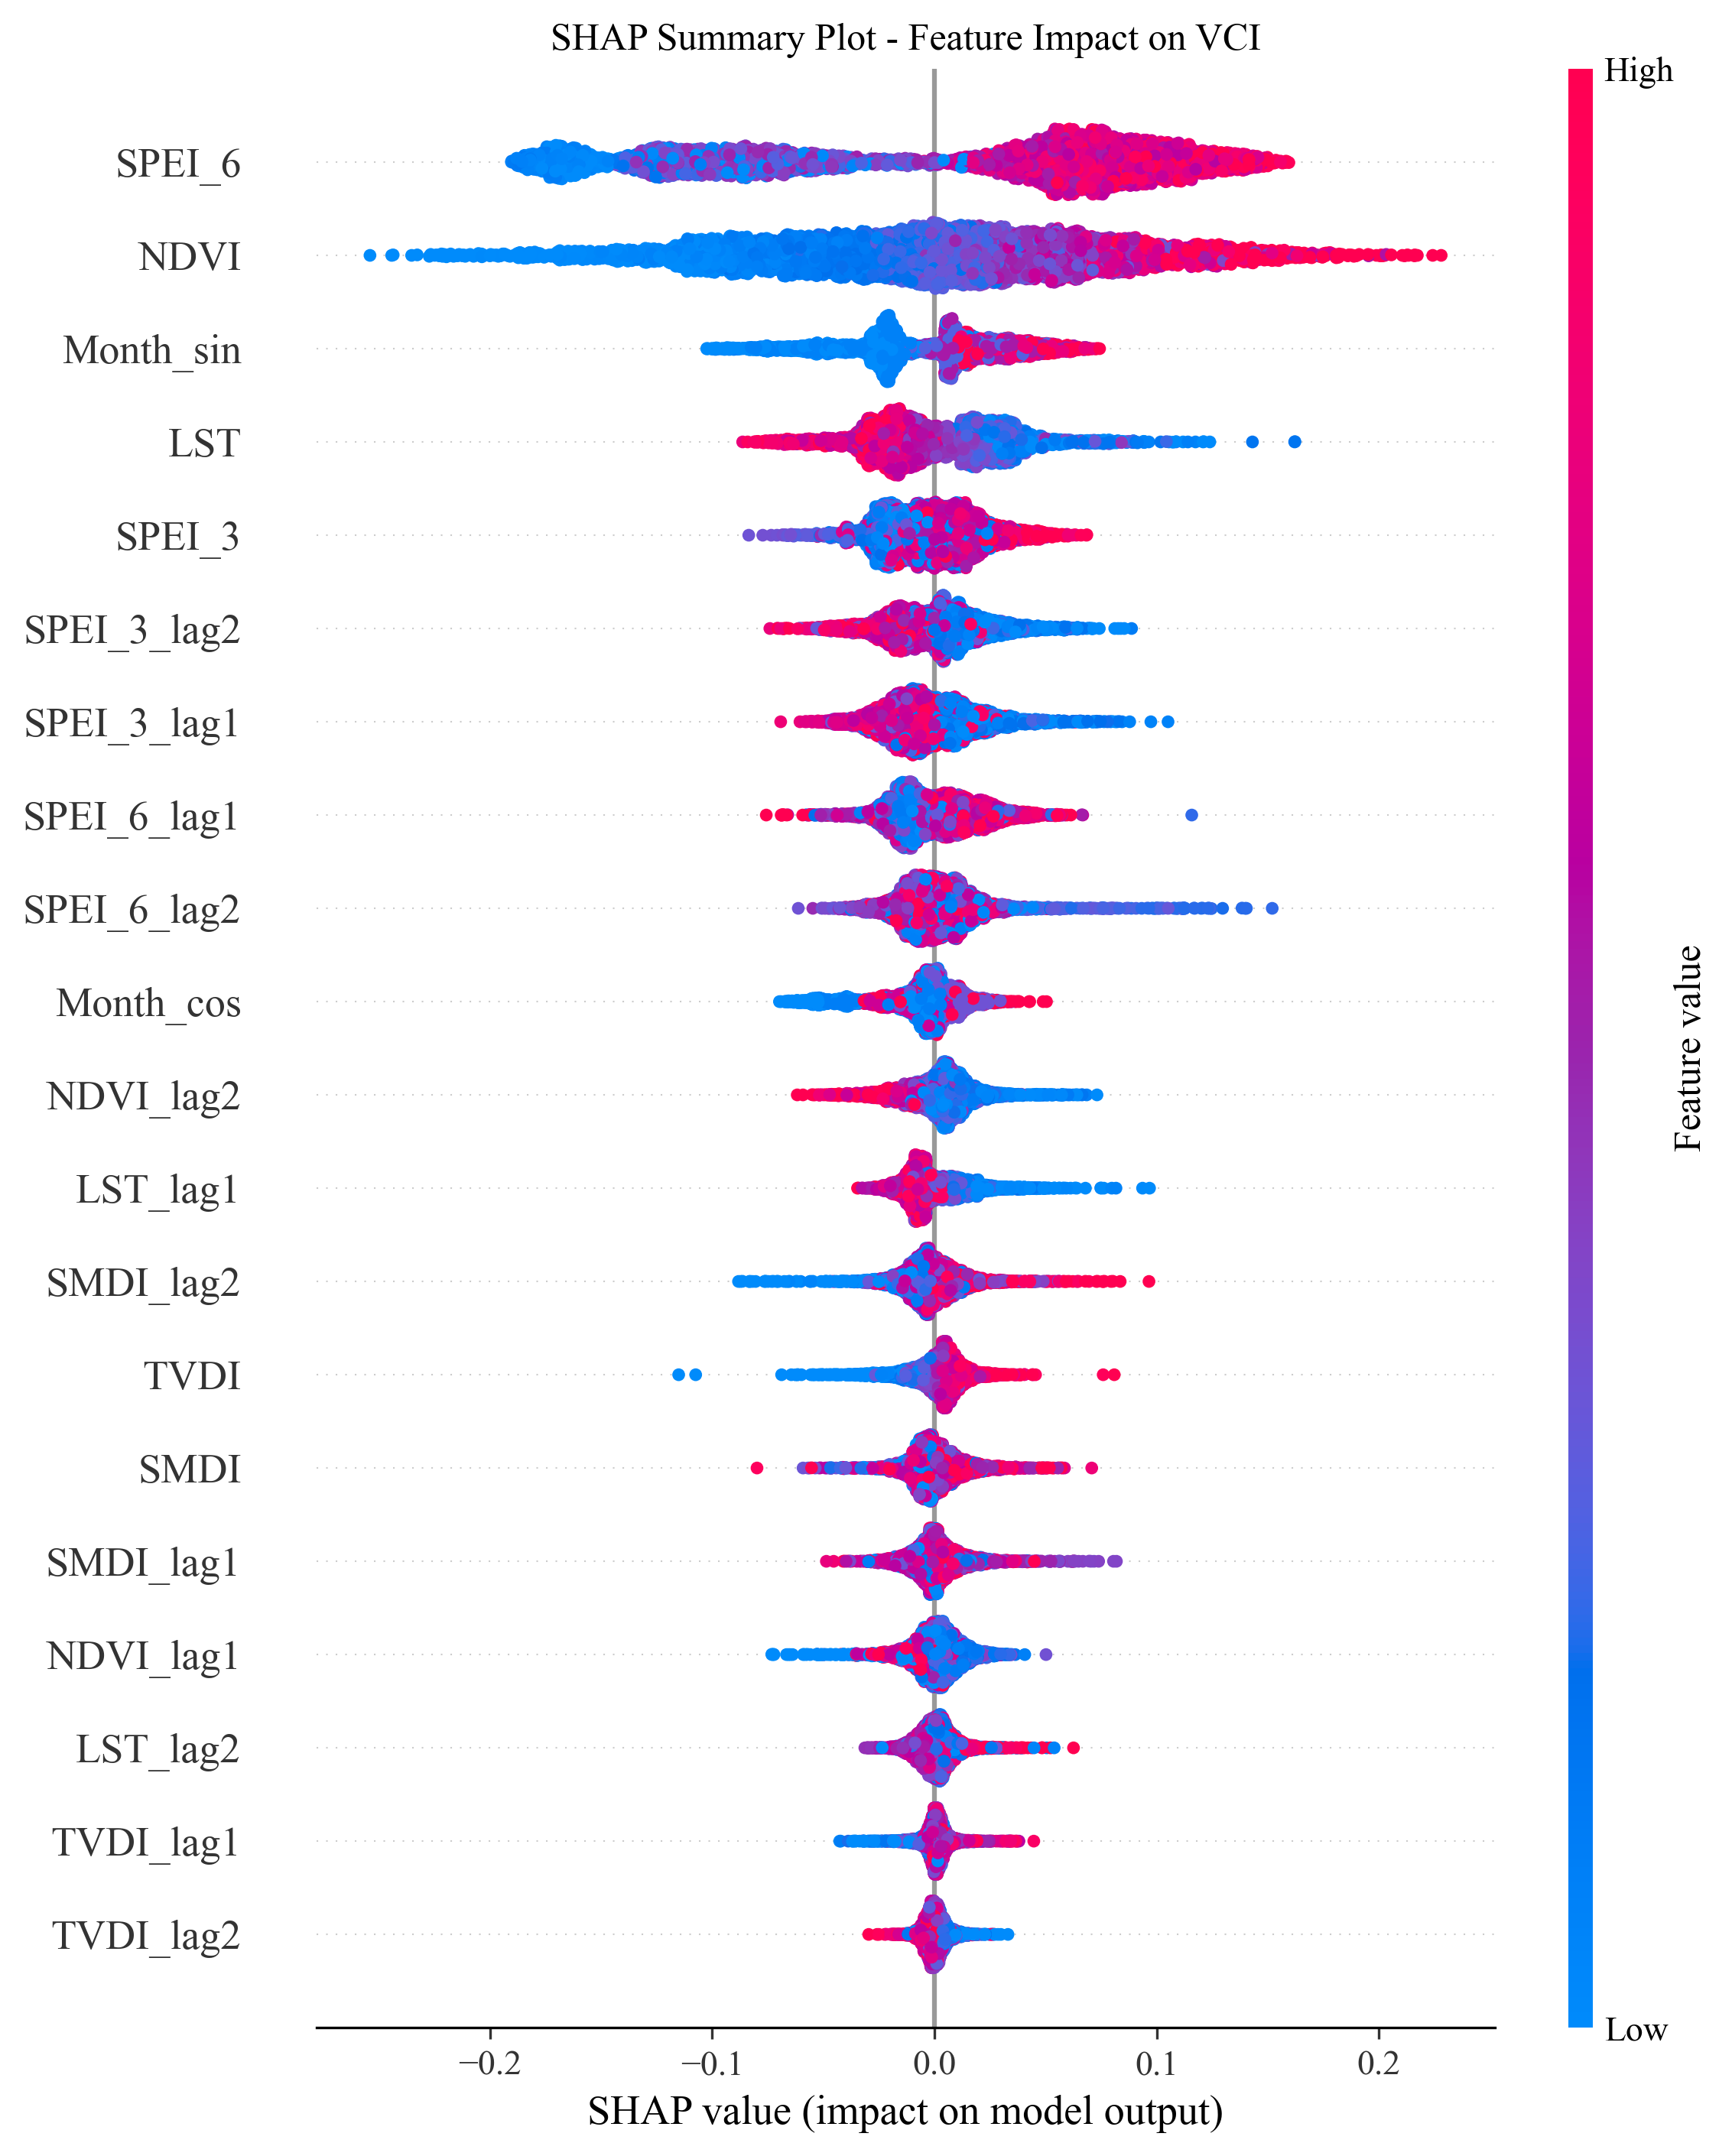

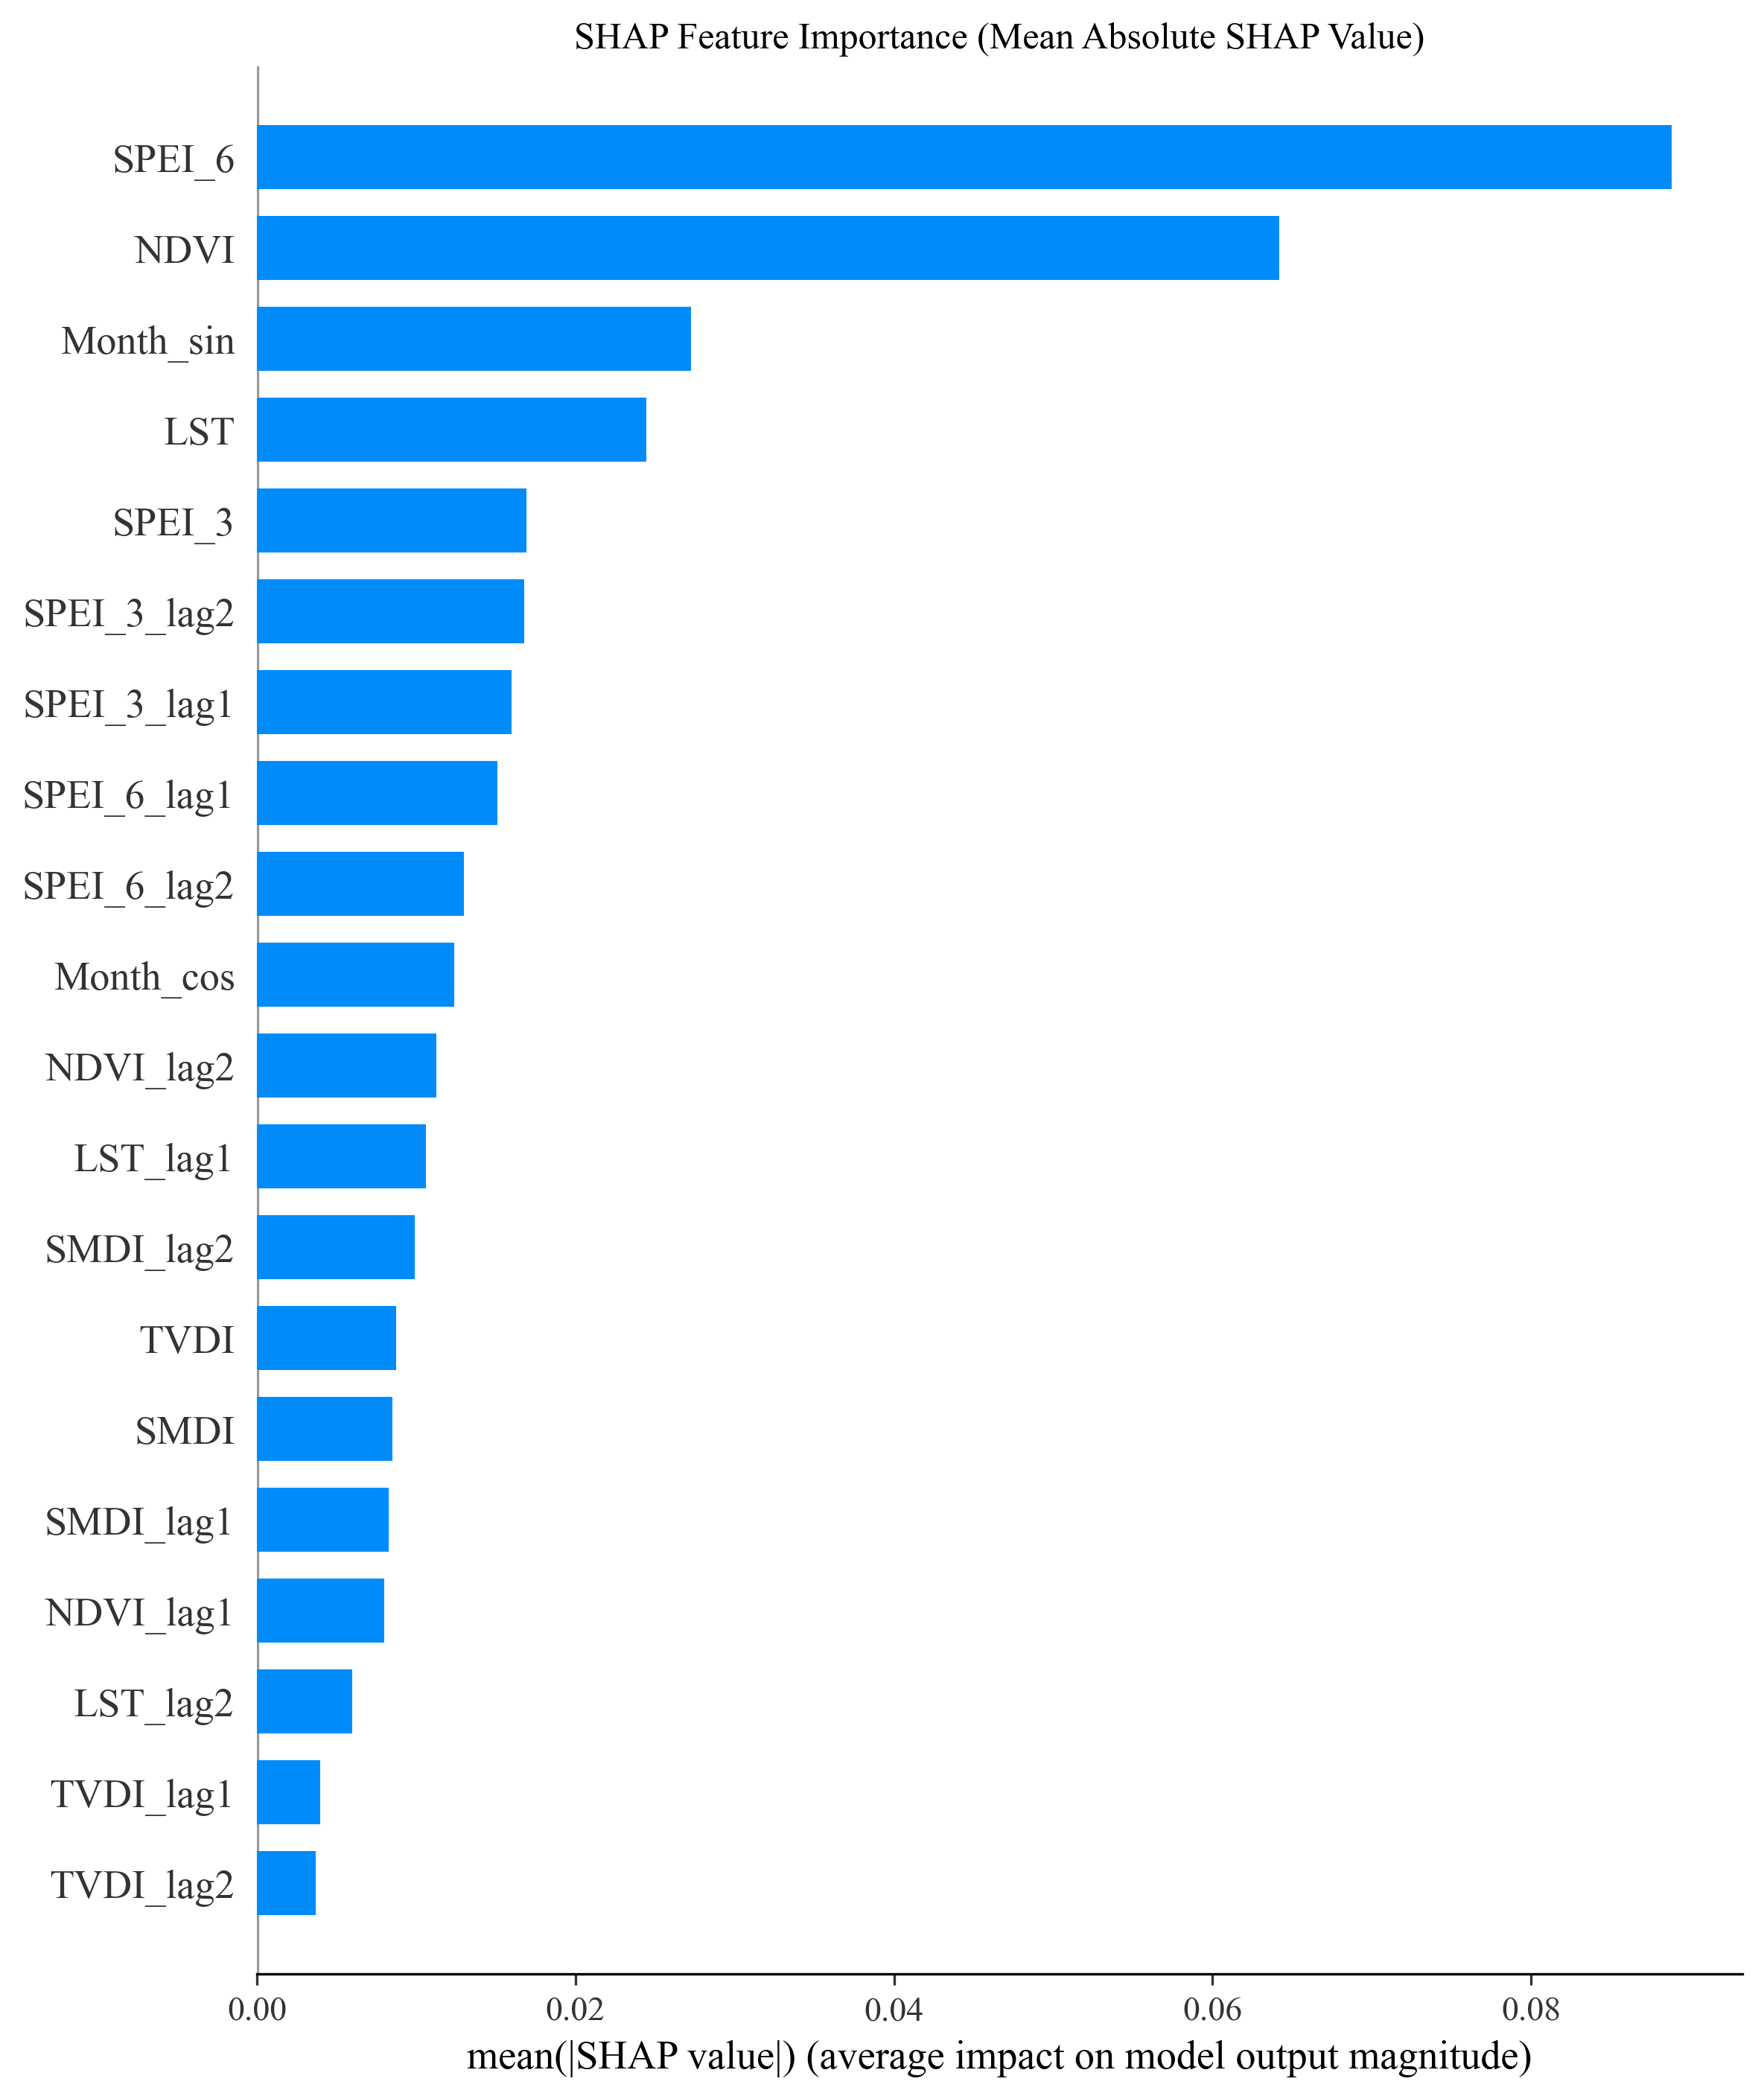


Generating SHAP Dependence Plots for Top 6 Features...
Top 6 Features for Dependence Plots: ['SPEI_6', 'NDVI', 'SPEI_3', 'SPEI_6_lag2', 'SPEI_6_lag1', 'SPEI_3_lag1']


<Figure size 2700x1800 with 0 Axes>

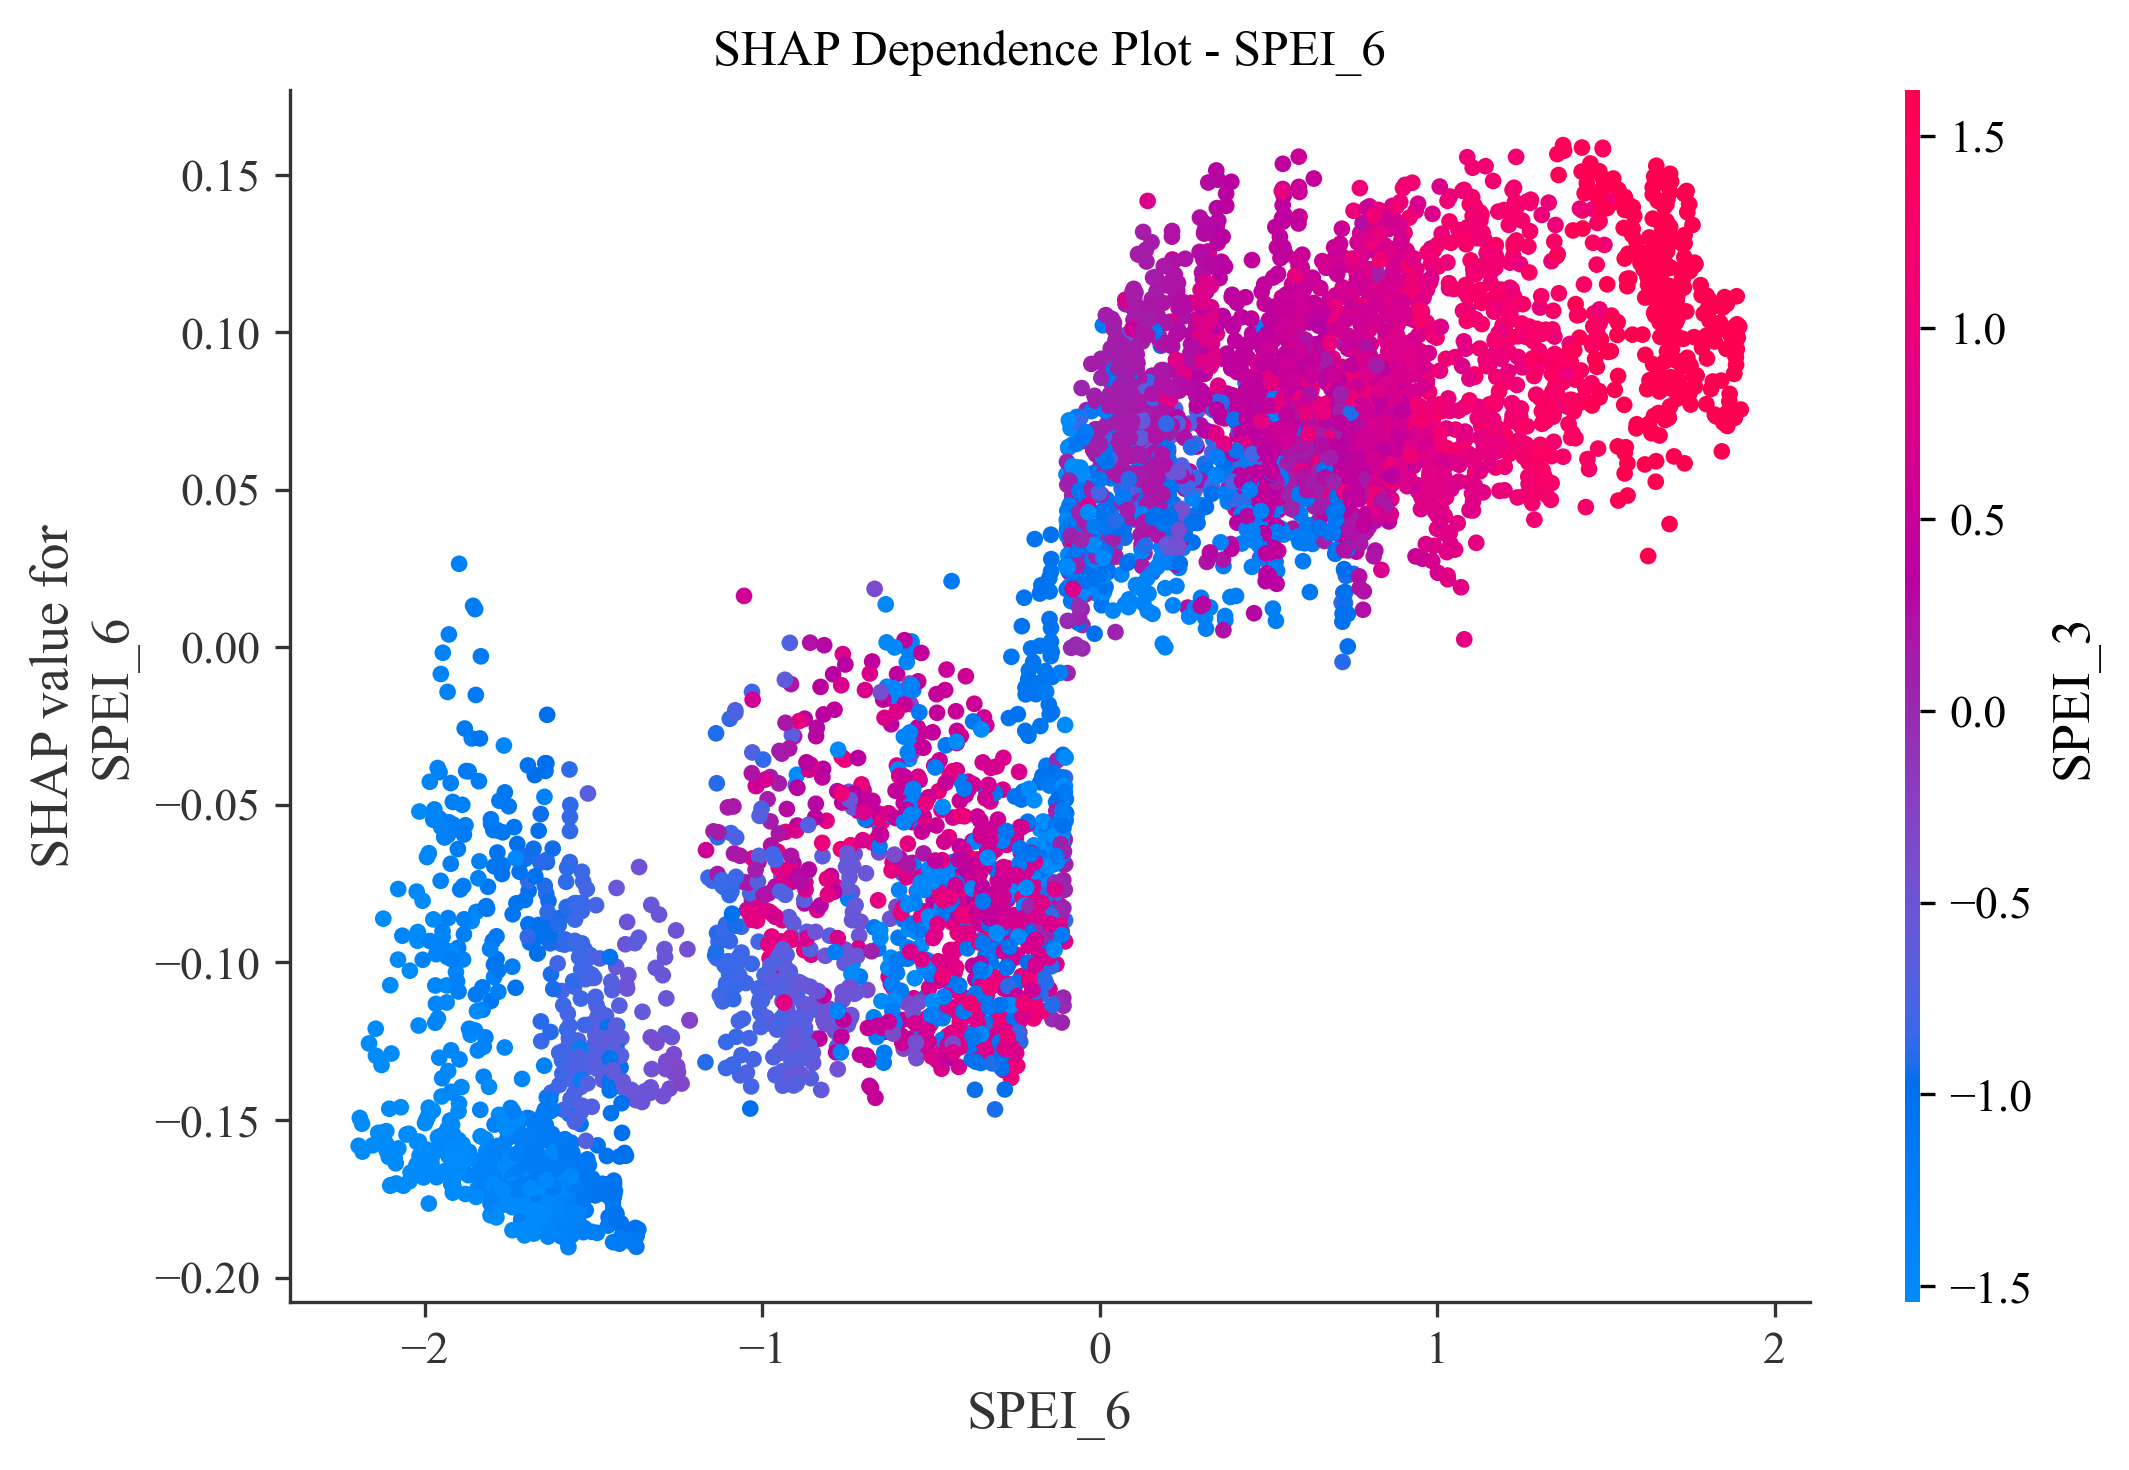

<Figure size 2700x1800 with 0 Axes>

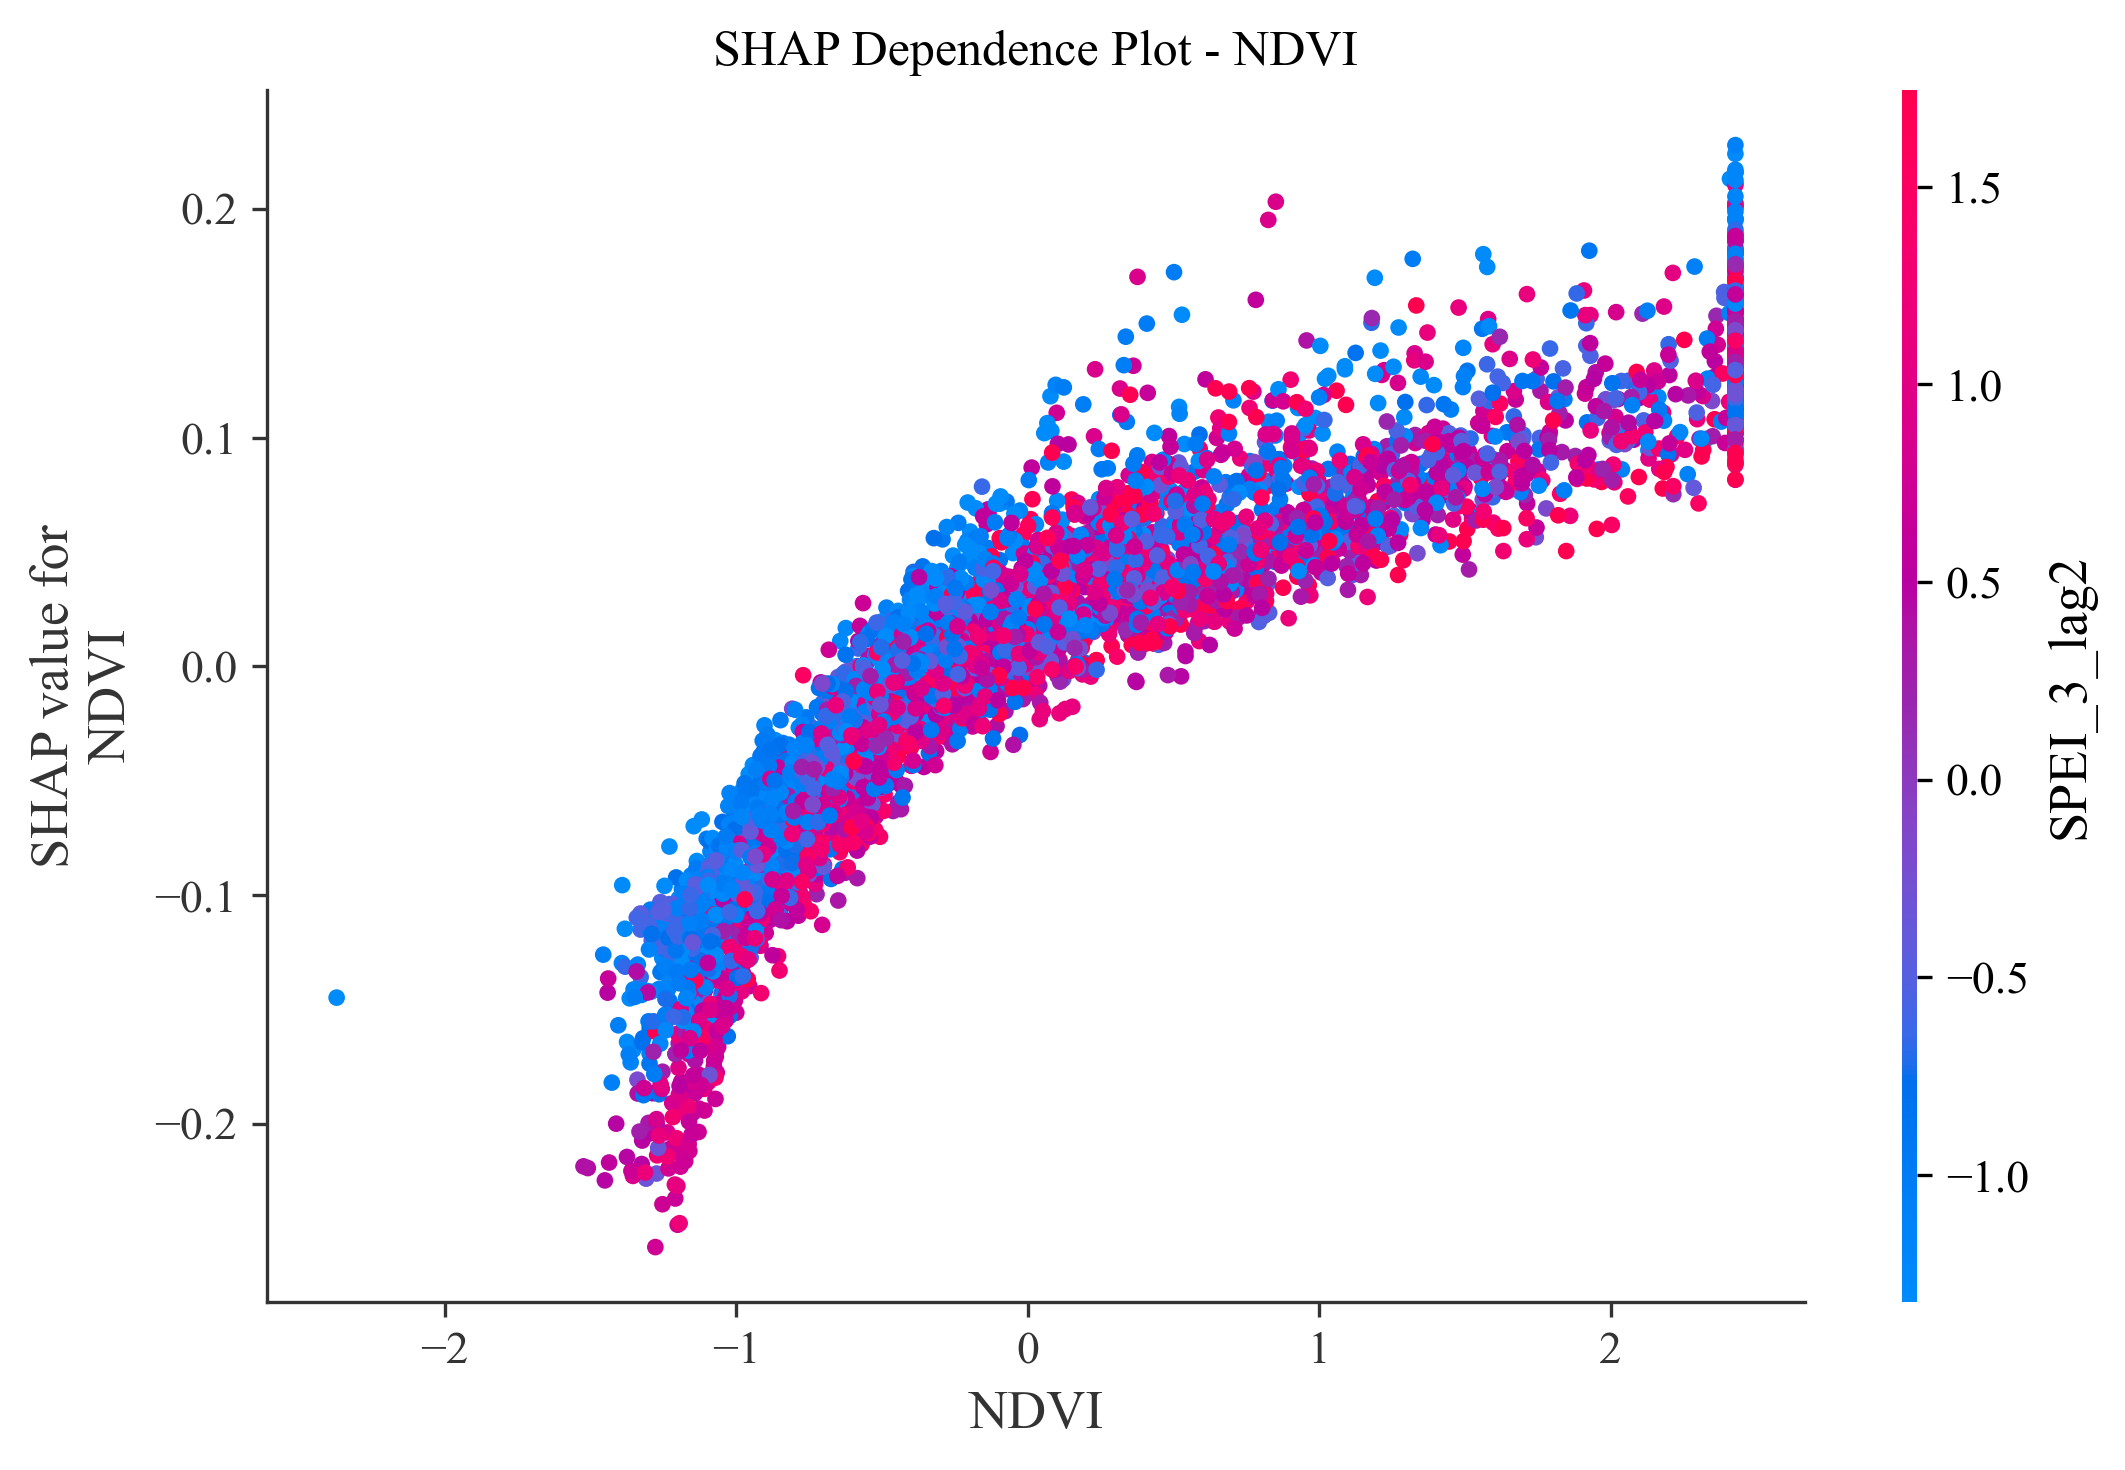

<Figure size 2700x1800 with 0 Axes>

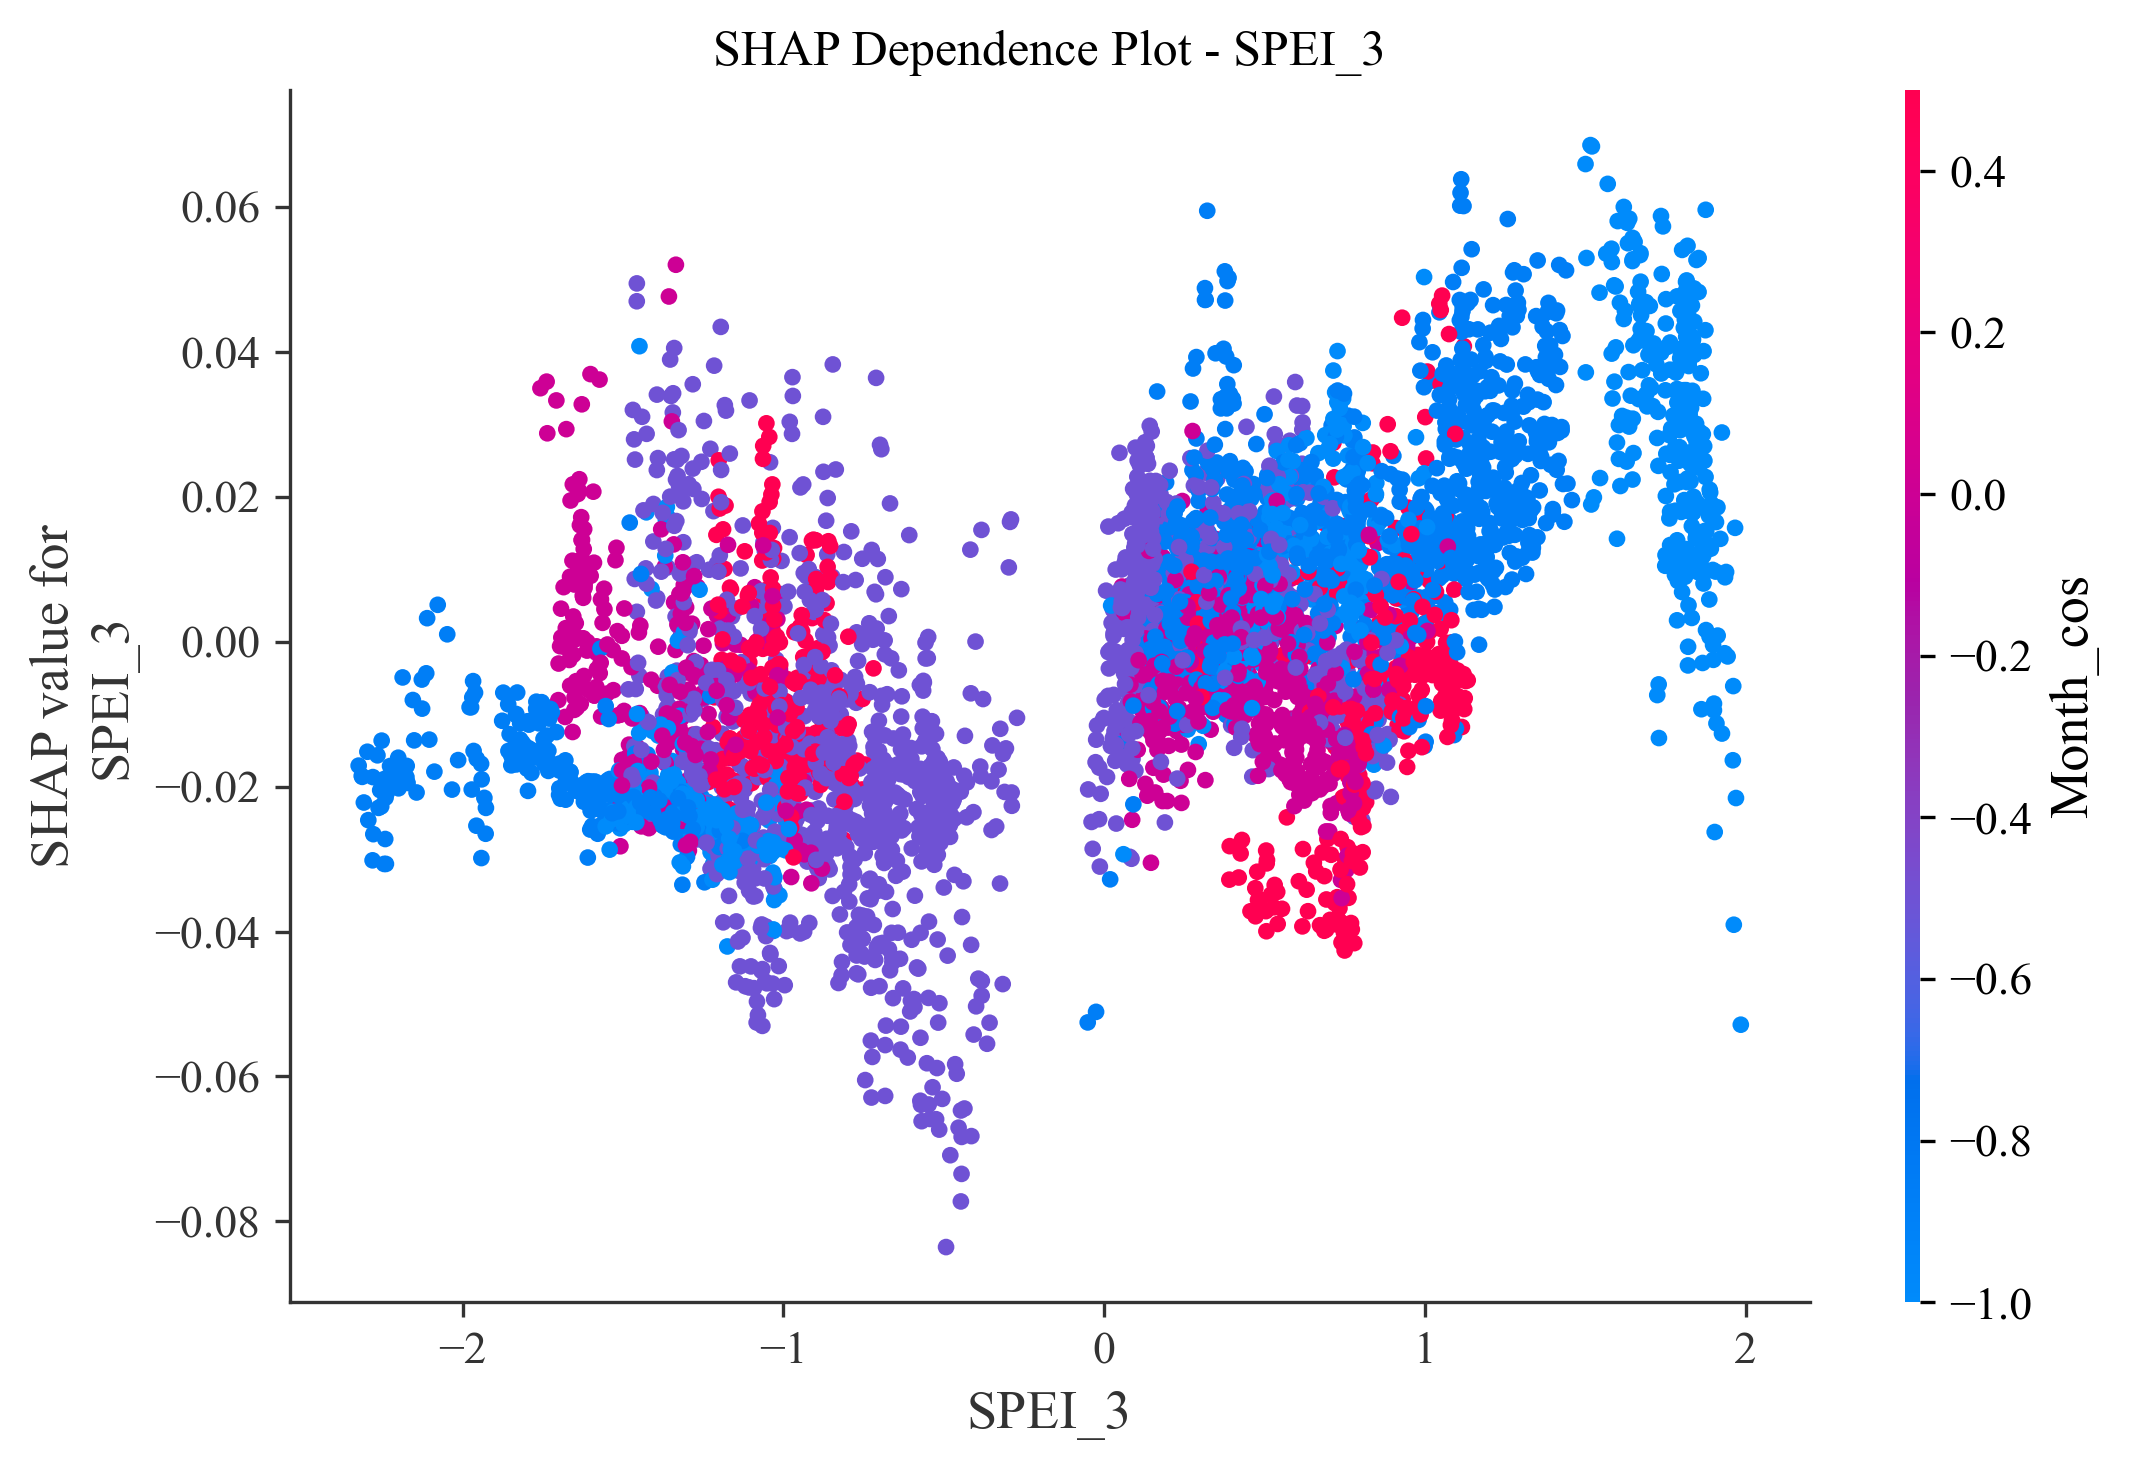

<Figure size 2700x1800 with 0 Axes>

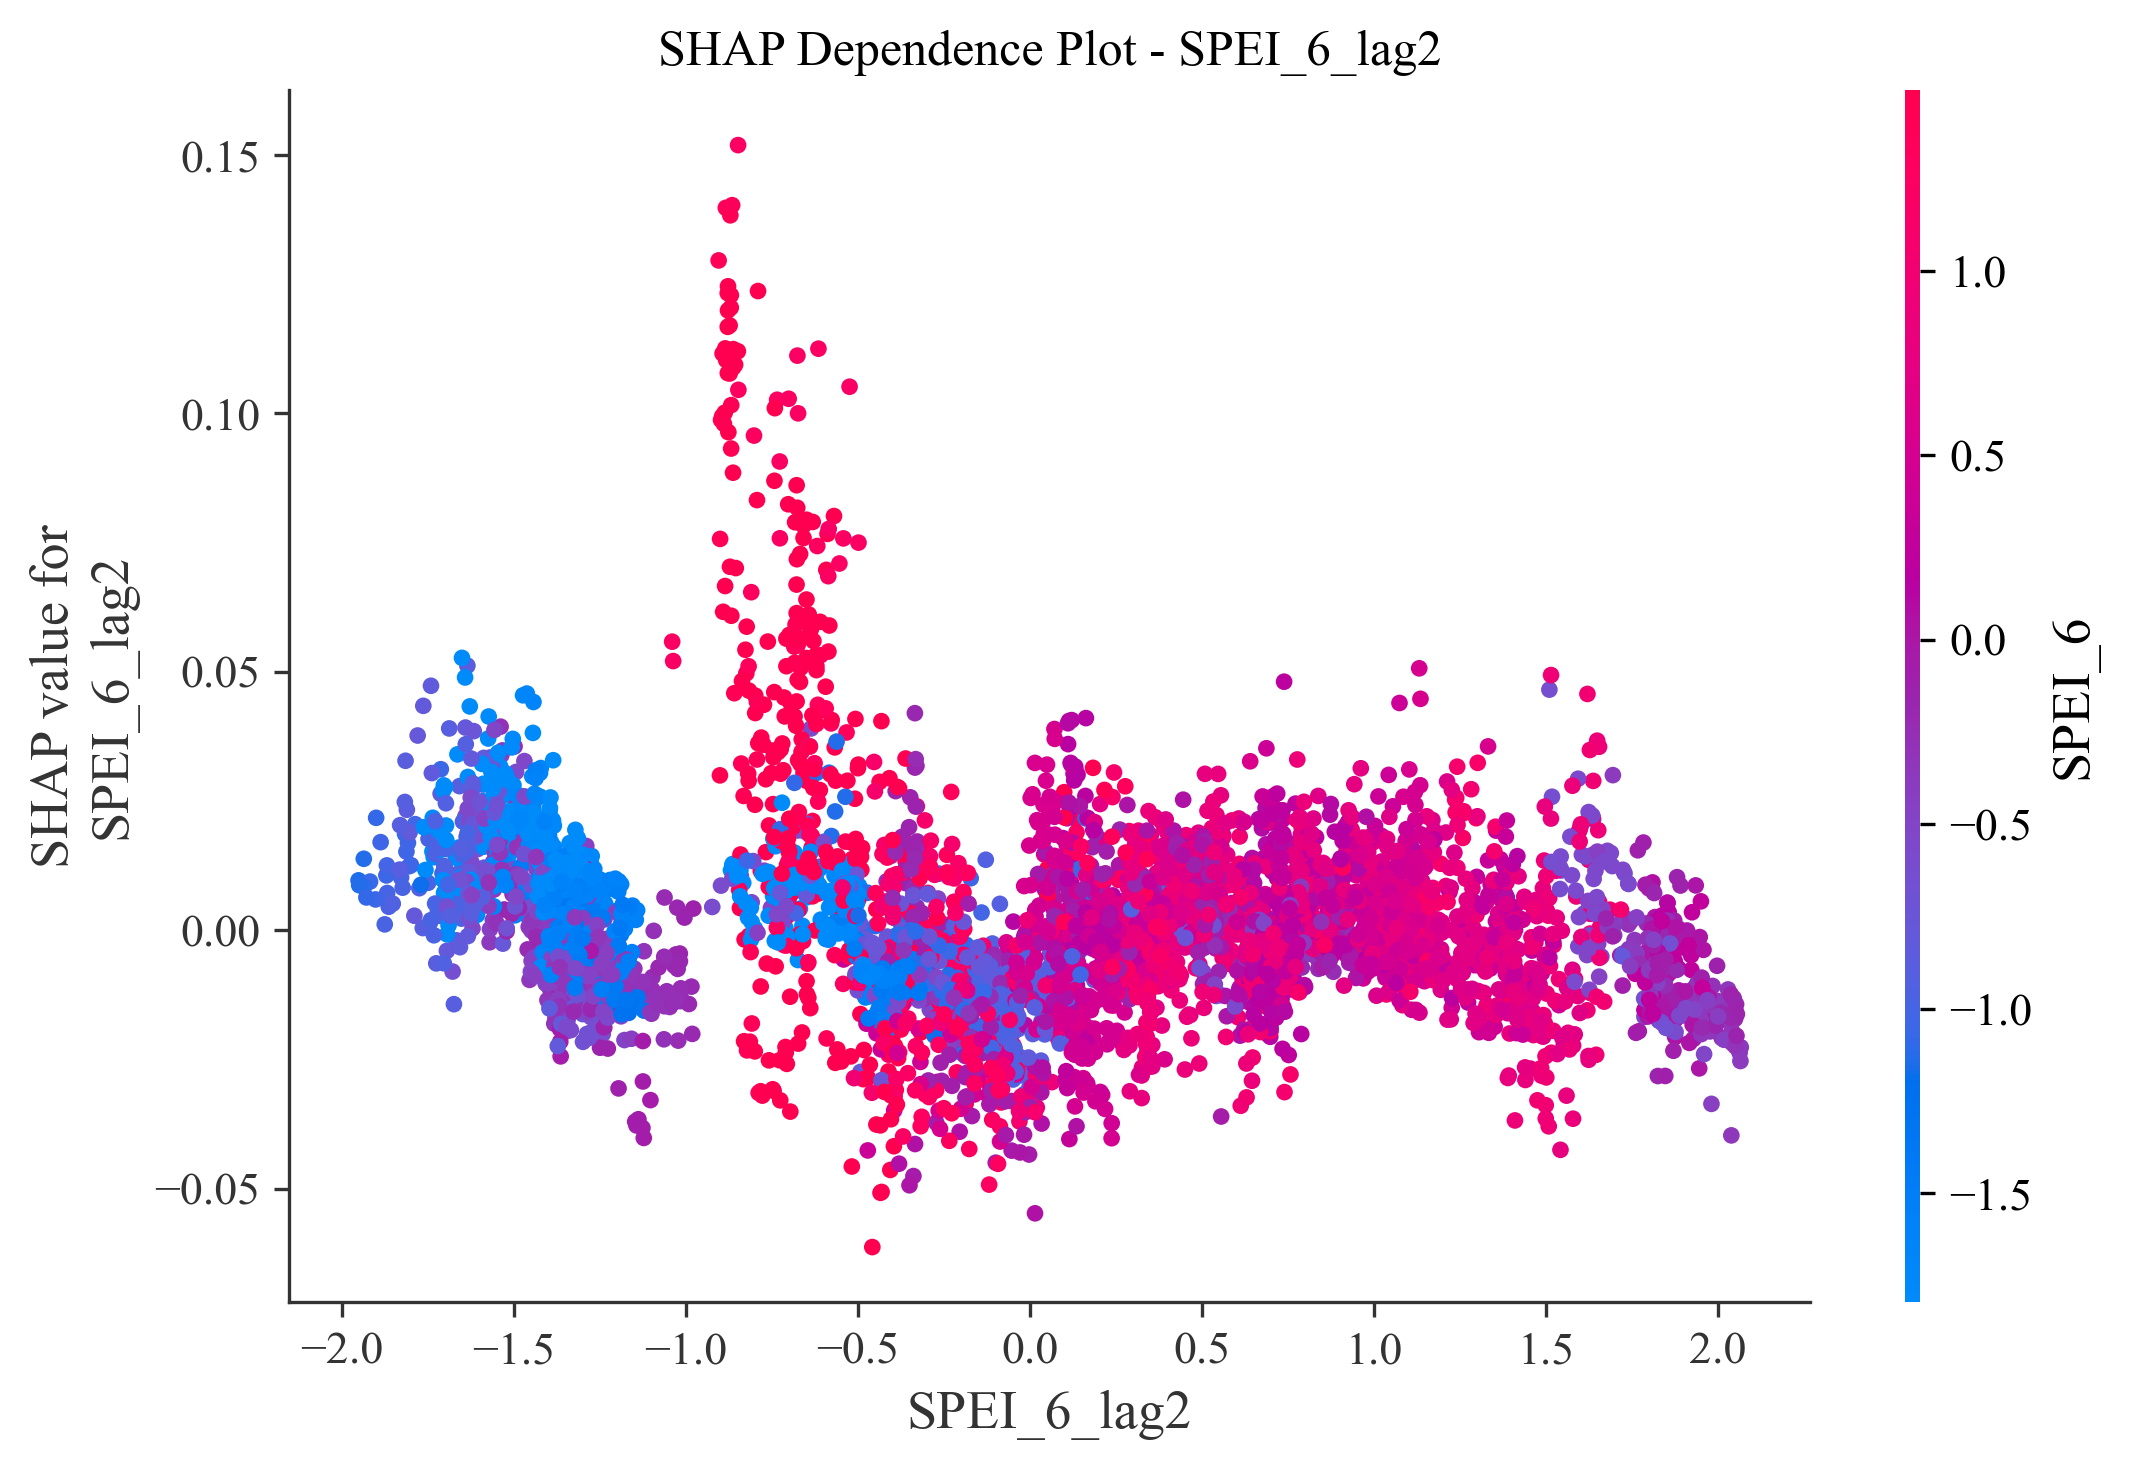

<Figure size 2700x1800 with 0 Axes>

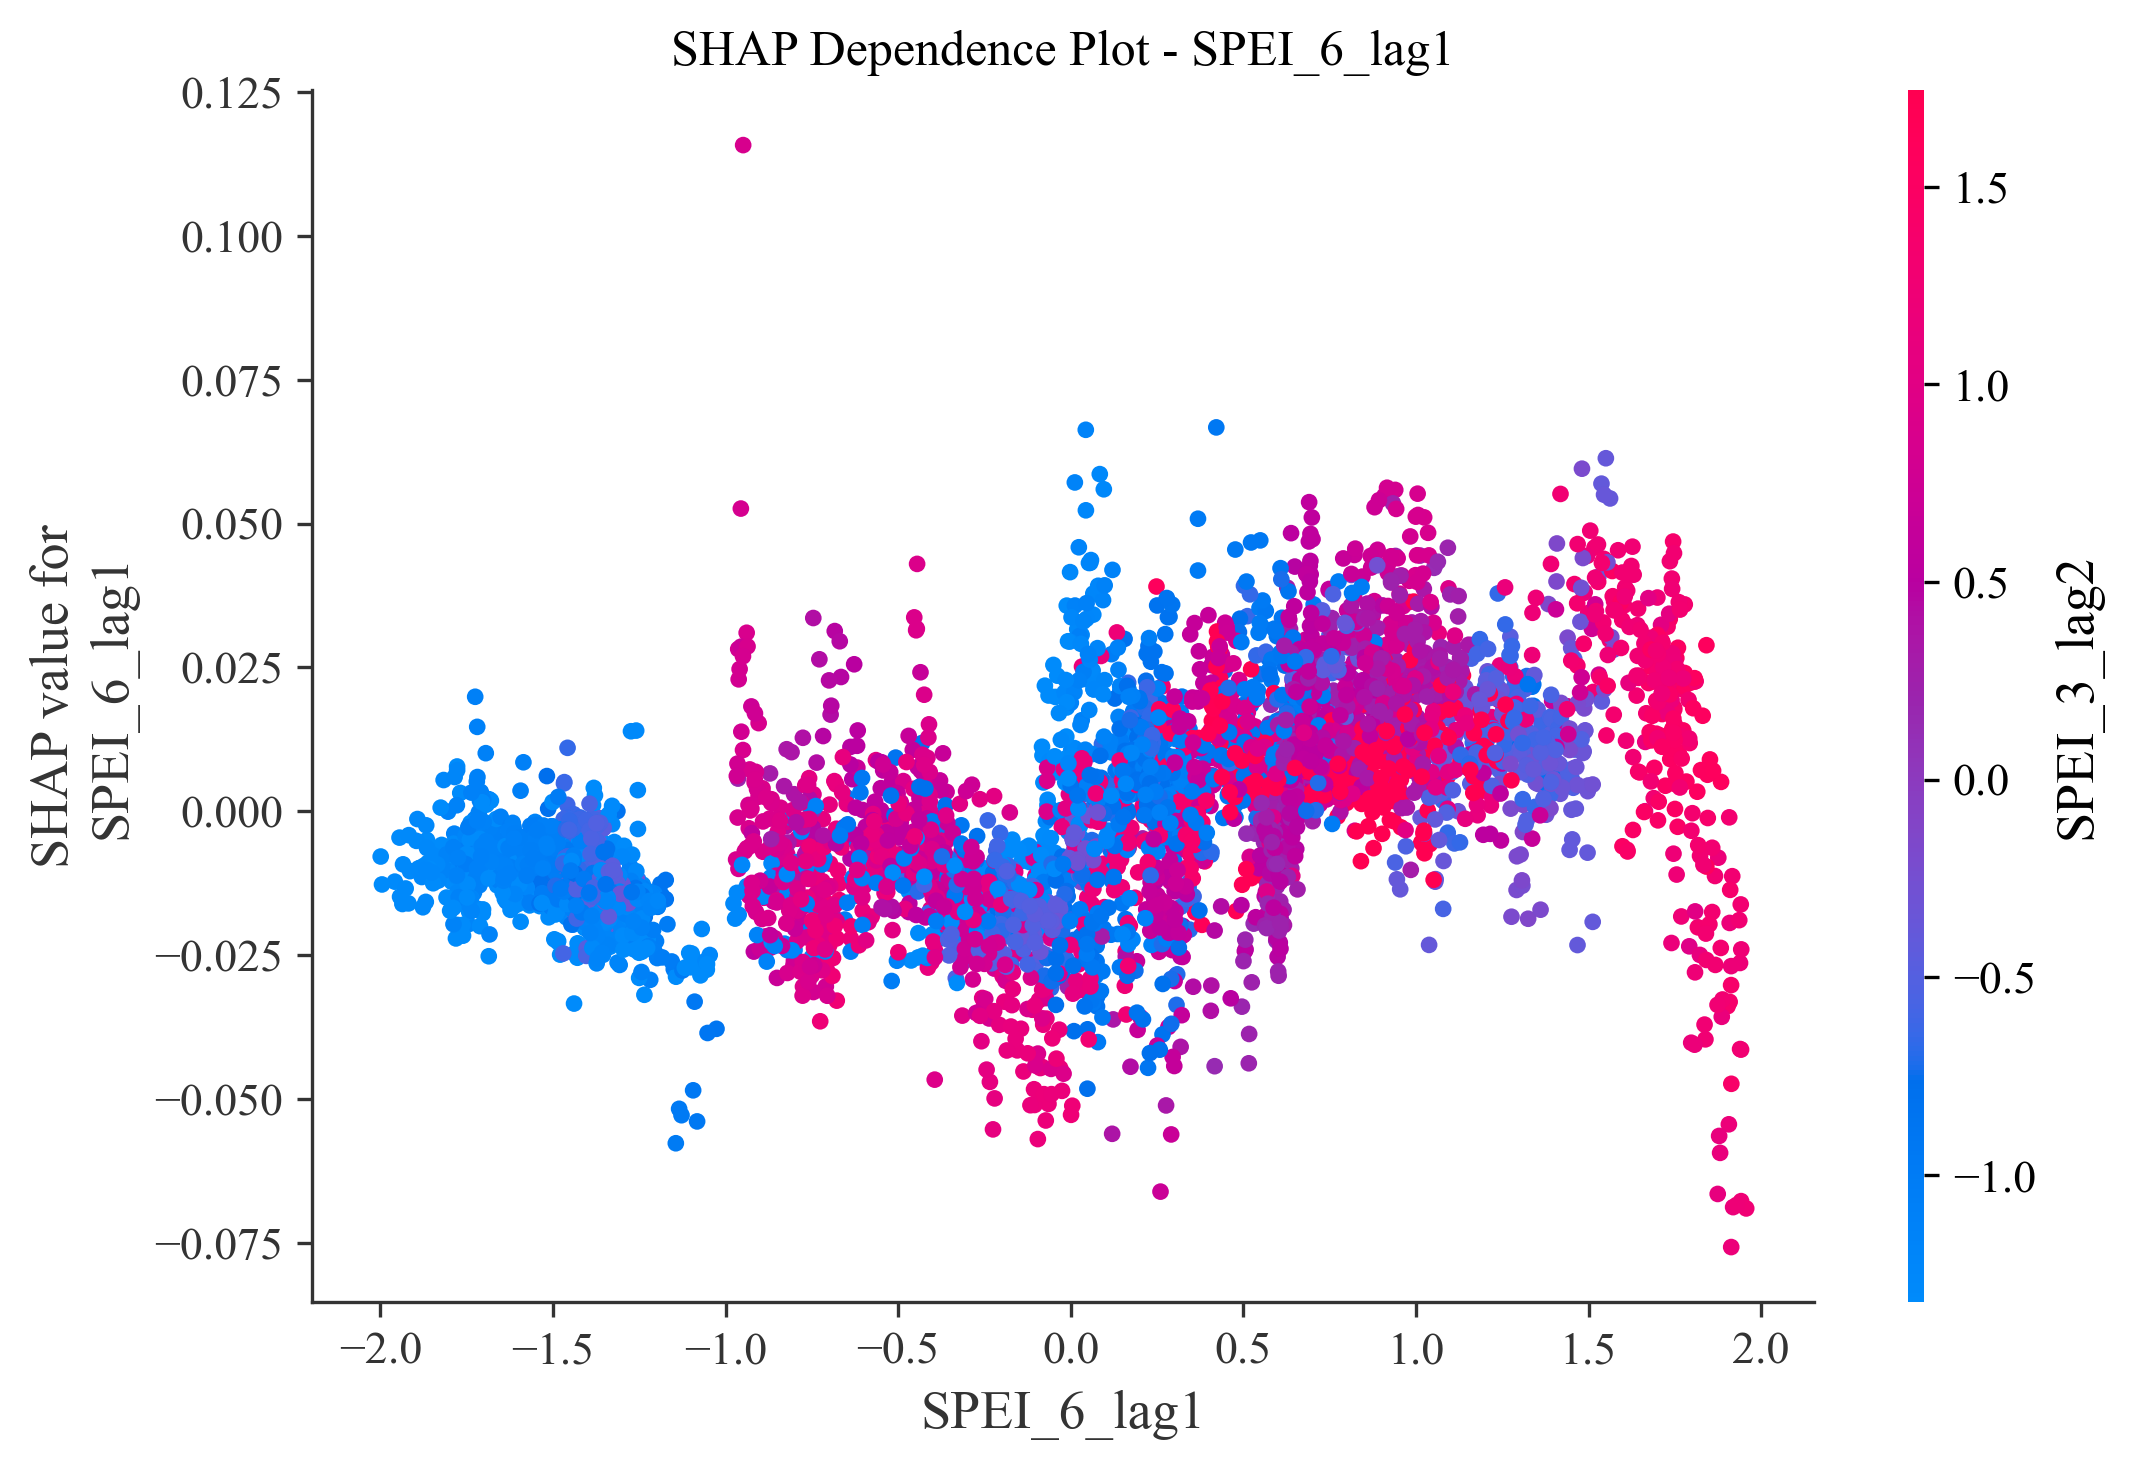

<Figure size 2700x1800 with 0 Axes>

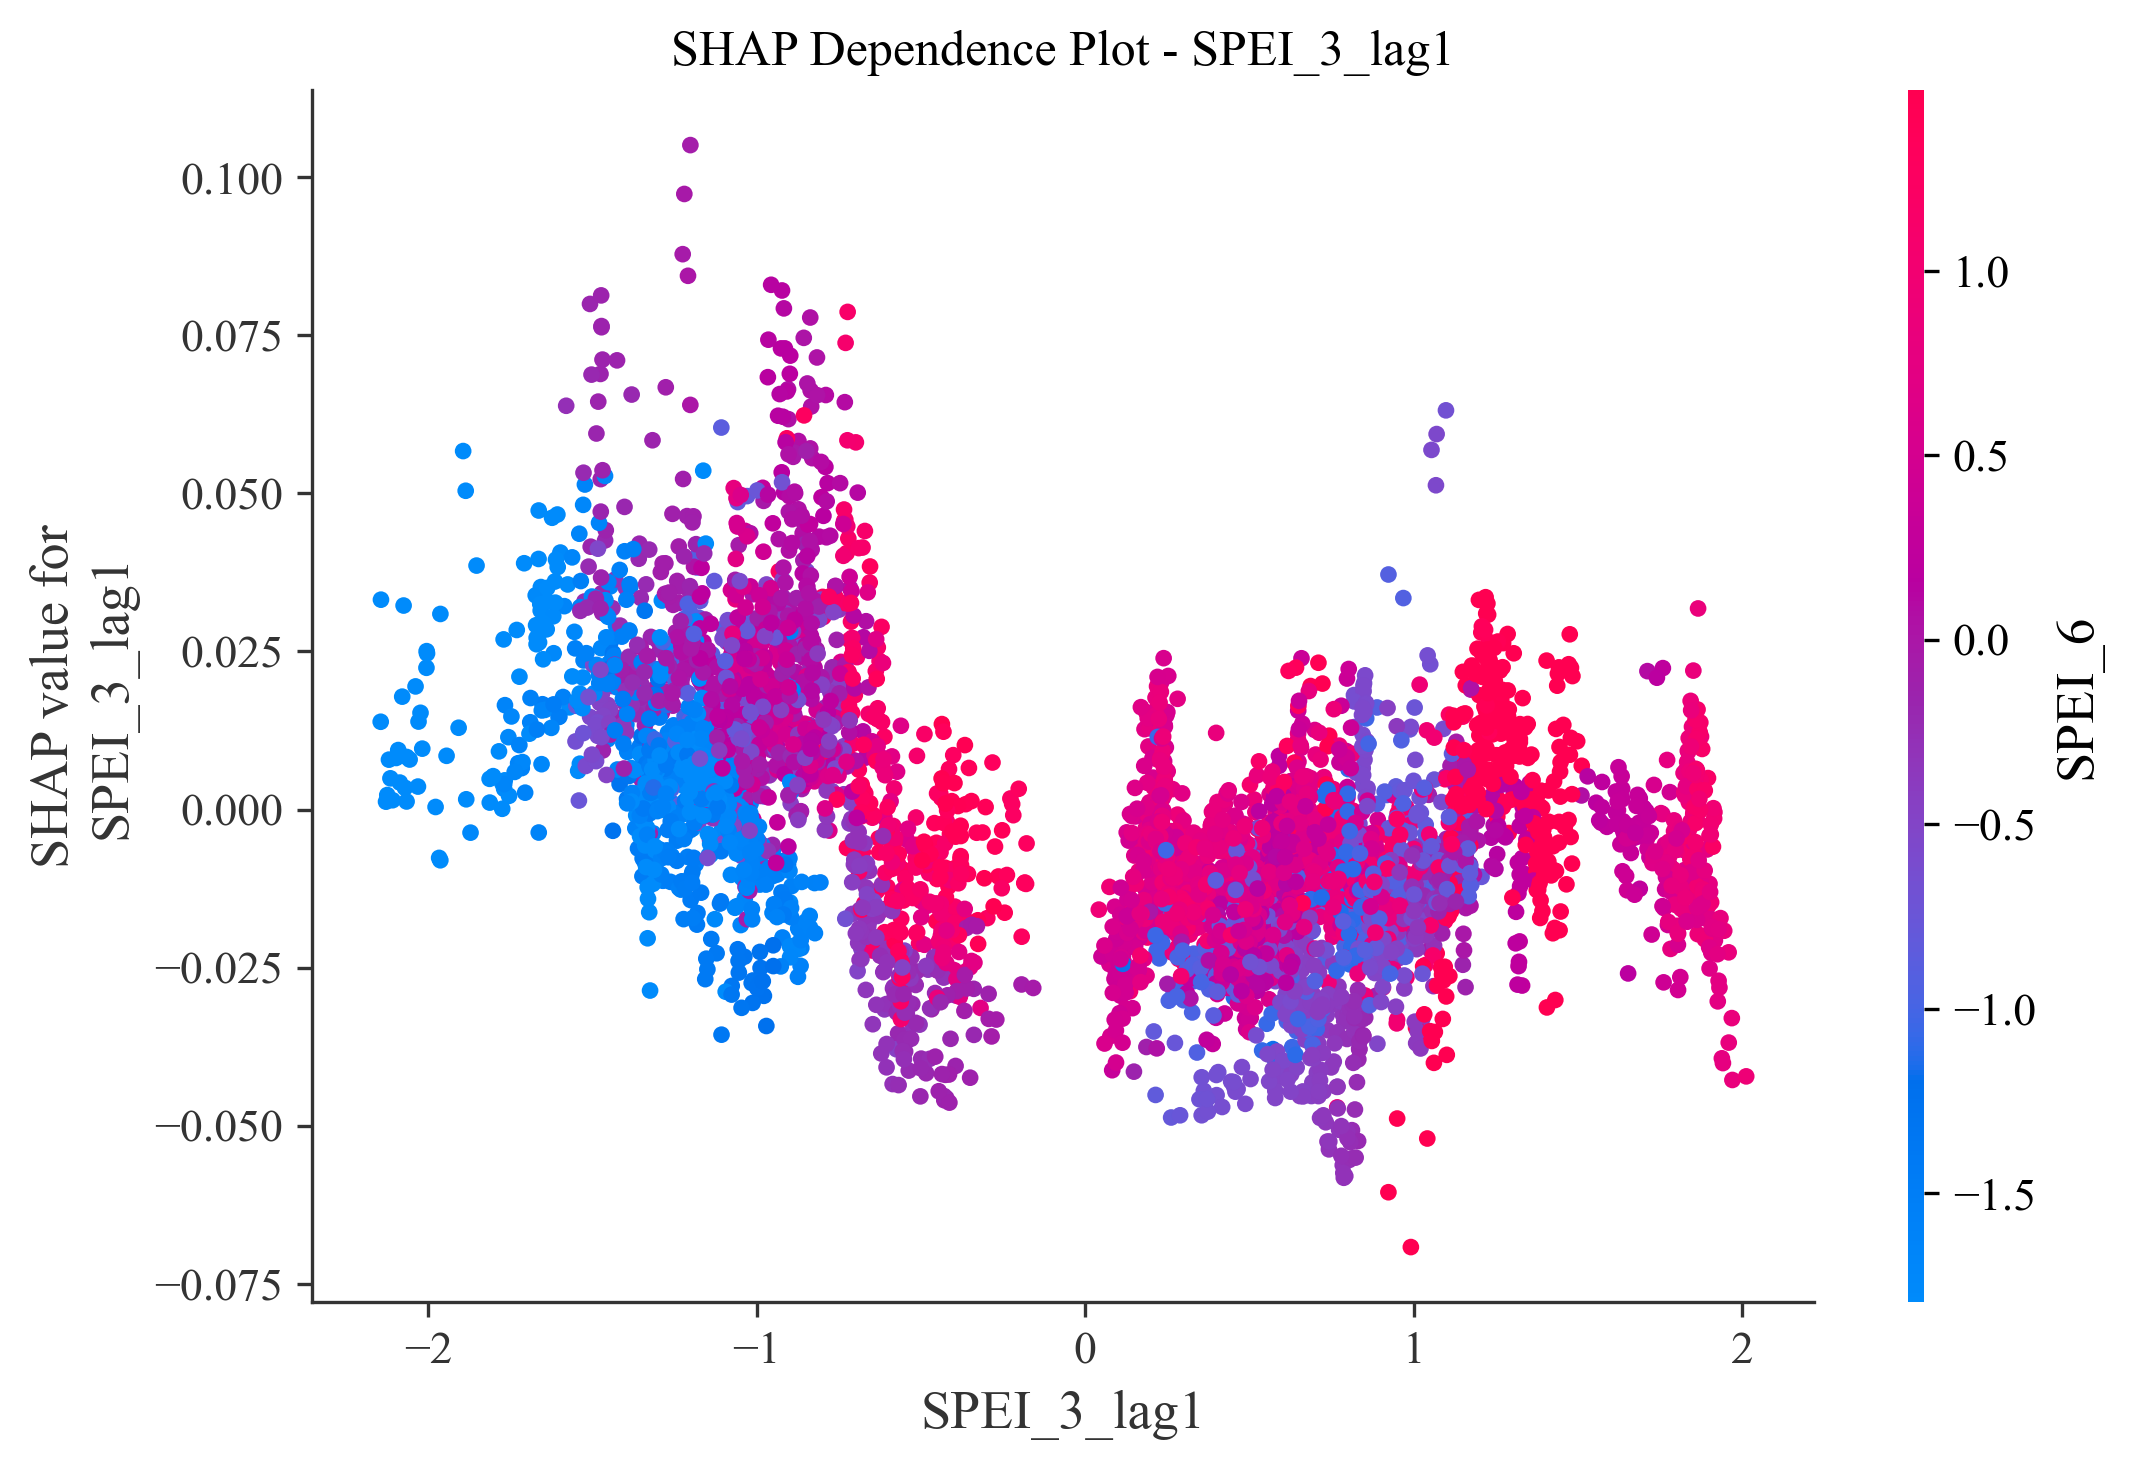


✅ All SHAP plots saved successfully in:
E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\shap analysis


In [4]:
# Final Model of Xgboost ======================================================================
# XGBoost + SHAP Analysis (70/30 Split) - Final Version
# ======================================================================
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
import shap

# ======================================================================
# REPRODUCIBILITY
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ======================================================================
# CREATE OUTPUT FOLDER
# ======================================================================
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\shap analysis"
os.makedirs(output_dir, exist_ok=True)
print(f"Plots will be saved to: {output_dir}")

# ======================================================================
# READ DATASET
# ======================================================================
print("\nReading Dataset...")
ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed"
input_csv = os.path.join(ml_dir, "lagged_ml_ready.csv")
df = pd.read_csv(input_csv)
print(f"Dataset Shape: {df.shape}")

# ======================================================================
# FEATURES & TARGET
# ======================================================================
drop_columns = ["VCI", "Row_Idx", "Col_Idx", "Year"]
X = df.drop(columns=drop_columns)
y = df["VCI"].copy()

# ======================================================================
# NORMALIZE TARGET
# ======================================================================
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

# ======================================================================
# 70/30 TRAIN-TEST SPLIT
# ======================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples : {len(X_test)}")

# ======================================================================
# TRAIN MODEL
# ======================================================================
print("\nTraining XGBoost...")
xgb_model = XGBRegressor(
    n_estimators=400,
    learning_rate=0.025,
    max_depth=16,
    min_child_weight=3,
    subsample=0.9,
    colsample_bytree=0.85,
    gamma=0.01,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective='reg:squarederror',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    eval_metric='rmse'
)

xgb_model.fit(X_train, y_train)
print("Training Completed.")

# ======================================================================
# PERFORMANCE SUMMARY
# ======================================================================
def evaluate_model(model, X_train, X_test, y_train, y_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {
        "train_r2": r2_score(y_train, train_pred),
        "test_r2": r2_score(y_test, test_pred),
        "train_rmse": np.sqrt(mean_squared_error(y_train, train_pred)),
        "test_rmse": np.sqrt(mean_squared_error(y_test, test_pred)),
        "train_mae": mean_absolute_error(y_train, train_pred),
        "test_mae": mean_absolute_error(y_test, test_pred)
    }

results = evaluate_model(xgb_model, X_train, X_test, y_train, y_test)

print("\n" + "="*70)
print("MODEL PERFORMANCE SUMMARY")
print("="*70)
print(f"Train R²   : {results['train_r2']:.4f}")
print(f"Test  R²   : {results['test_r2']:.4f}")
print(f"Train RMSE : {results['train_rmse']:.4f}")
print(f"Test  RMSE : {results['test_rmse']:.4f}")
print(f"Train MAE  : {results['train_mae']:.4f}")
print(f"Test  MAE  : {results['test_mae']:.4f}")
print("="*70)

# ======================================================================
# SHAP ANALYSIS
# ======================================================================
print("\nComputing SHAP values...")
explainer = shap.TreeExplainer(xgb_model)

# Sample for faster computation
X_test_sample = X_test.iloc[:5000]
shap_values = explainer.shap_values(X_test_sample)

# 1. SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(10, 8), dpi=300)
shap.summary_plot(shap_values, X_test_sample, max_display=20, show=False)
plt.title("SHAP Summary Plot - Feature Impact on VCI")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "SHAP_Summary_Beeswarm.png"), dpi=300, bbox_inches='tight')
plt.show()

# 2. SHAP Summary Bar Plot
plt.figure(figsize=(10, 8), dpi=300)
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", max_display=20, show=False)
plt.title("SHAP Feature Importance (Mean Absolute SHAP Value)")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "SHAP_Feature_Importance_Bar.png"), dpi=300, bbox_inches='tight')
plt.show()

# ======================================================================
# SHAP DEPENDENCE PLOTS - Top 6 Features (Excluding Month_sin/cos)
# ======================================================================
print("\nGenerating SHAP Dependence Plots for Top 6 Features...")

# Get top 6 features by importance (excluding month features)
importance = xgb_model.feature_importances_
feat_names = X_train.columns
feat_imp = pd.DataFrame({'Feature': feat_names, 'Importance': importance})
feat_imp = feat_imp.sort_values('Importance', ascending=False)

# Filter out month features for dependence plots
top_features = [f for f in feat_imp['Feature'].head(10) 
                if 'month' not in f.lower()][:6]

print("Top 6 Features for Dependence Plots:", top_features)

for feature in top_features:
    plt.figure(figsize=(9, 6), dpi=300)
    shap.dependence_plot(
        feature, 
        shap_values, 
        X_test_sample, 
        show=False,
        interaction_index='auto'
    )
    plt.title(f"SHAP Dependence Plot - {feature}")
    plt.tight_layout()
    safe_name = feature.replace("_", "-").replace("/", "-")
    plt.savefig(os.path.join(output_dir, f"SHAP_Dependence_{safe_name}.png"), 
                dpi=300, bbox_inches='tight')
    plt.show()

print(f"\n✅ All SHAP plots saved successfully in:\n{output_dir}")


Computing Permutation Feature Importance...

Top 15 Features by Permutation Importance:
        Feature  Mean_Importance
3          NDVI         0.519894
6        SPEI_6         0.450247
0     Month_sin         0.136886
2           LST         0.110364
17  SPEI_6_lag2         0.108068
16  SPEI_6_lag1         0.098087
15  SPEI_3_lag2         0.093011
14  SPEI_3_lag1         0.090255
5        SPEI_3         0.088136
4          SMDI         0.073535
13    SMDI_lag2         0.070867
12    SMDI_lag1         0.060715
11    NDVI_lag2         0.059625
1     Month_cos         0.052139
10    NDVI_lag1         0.042743


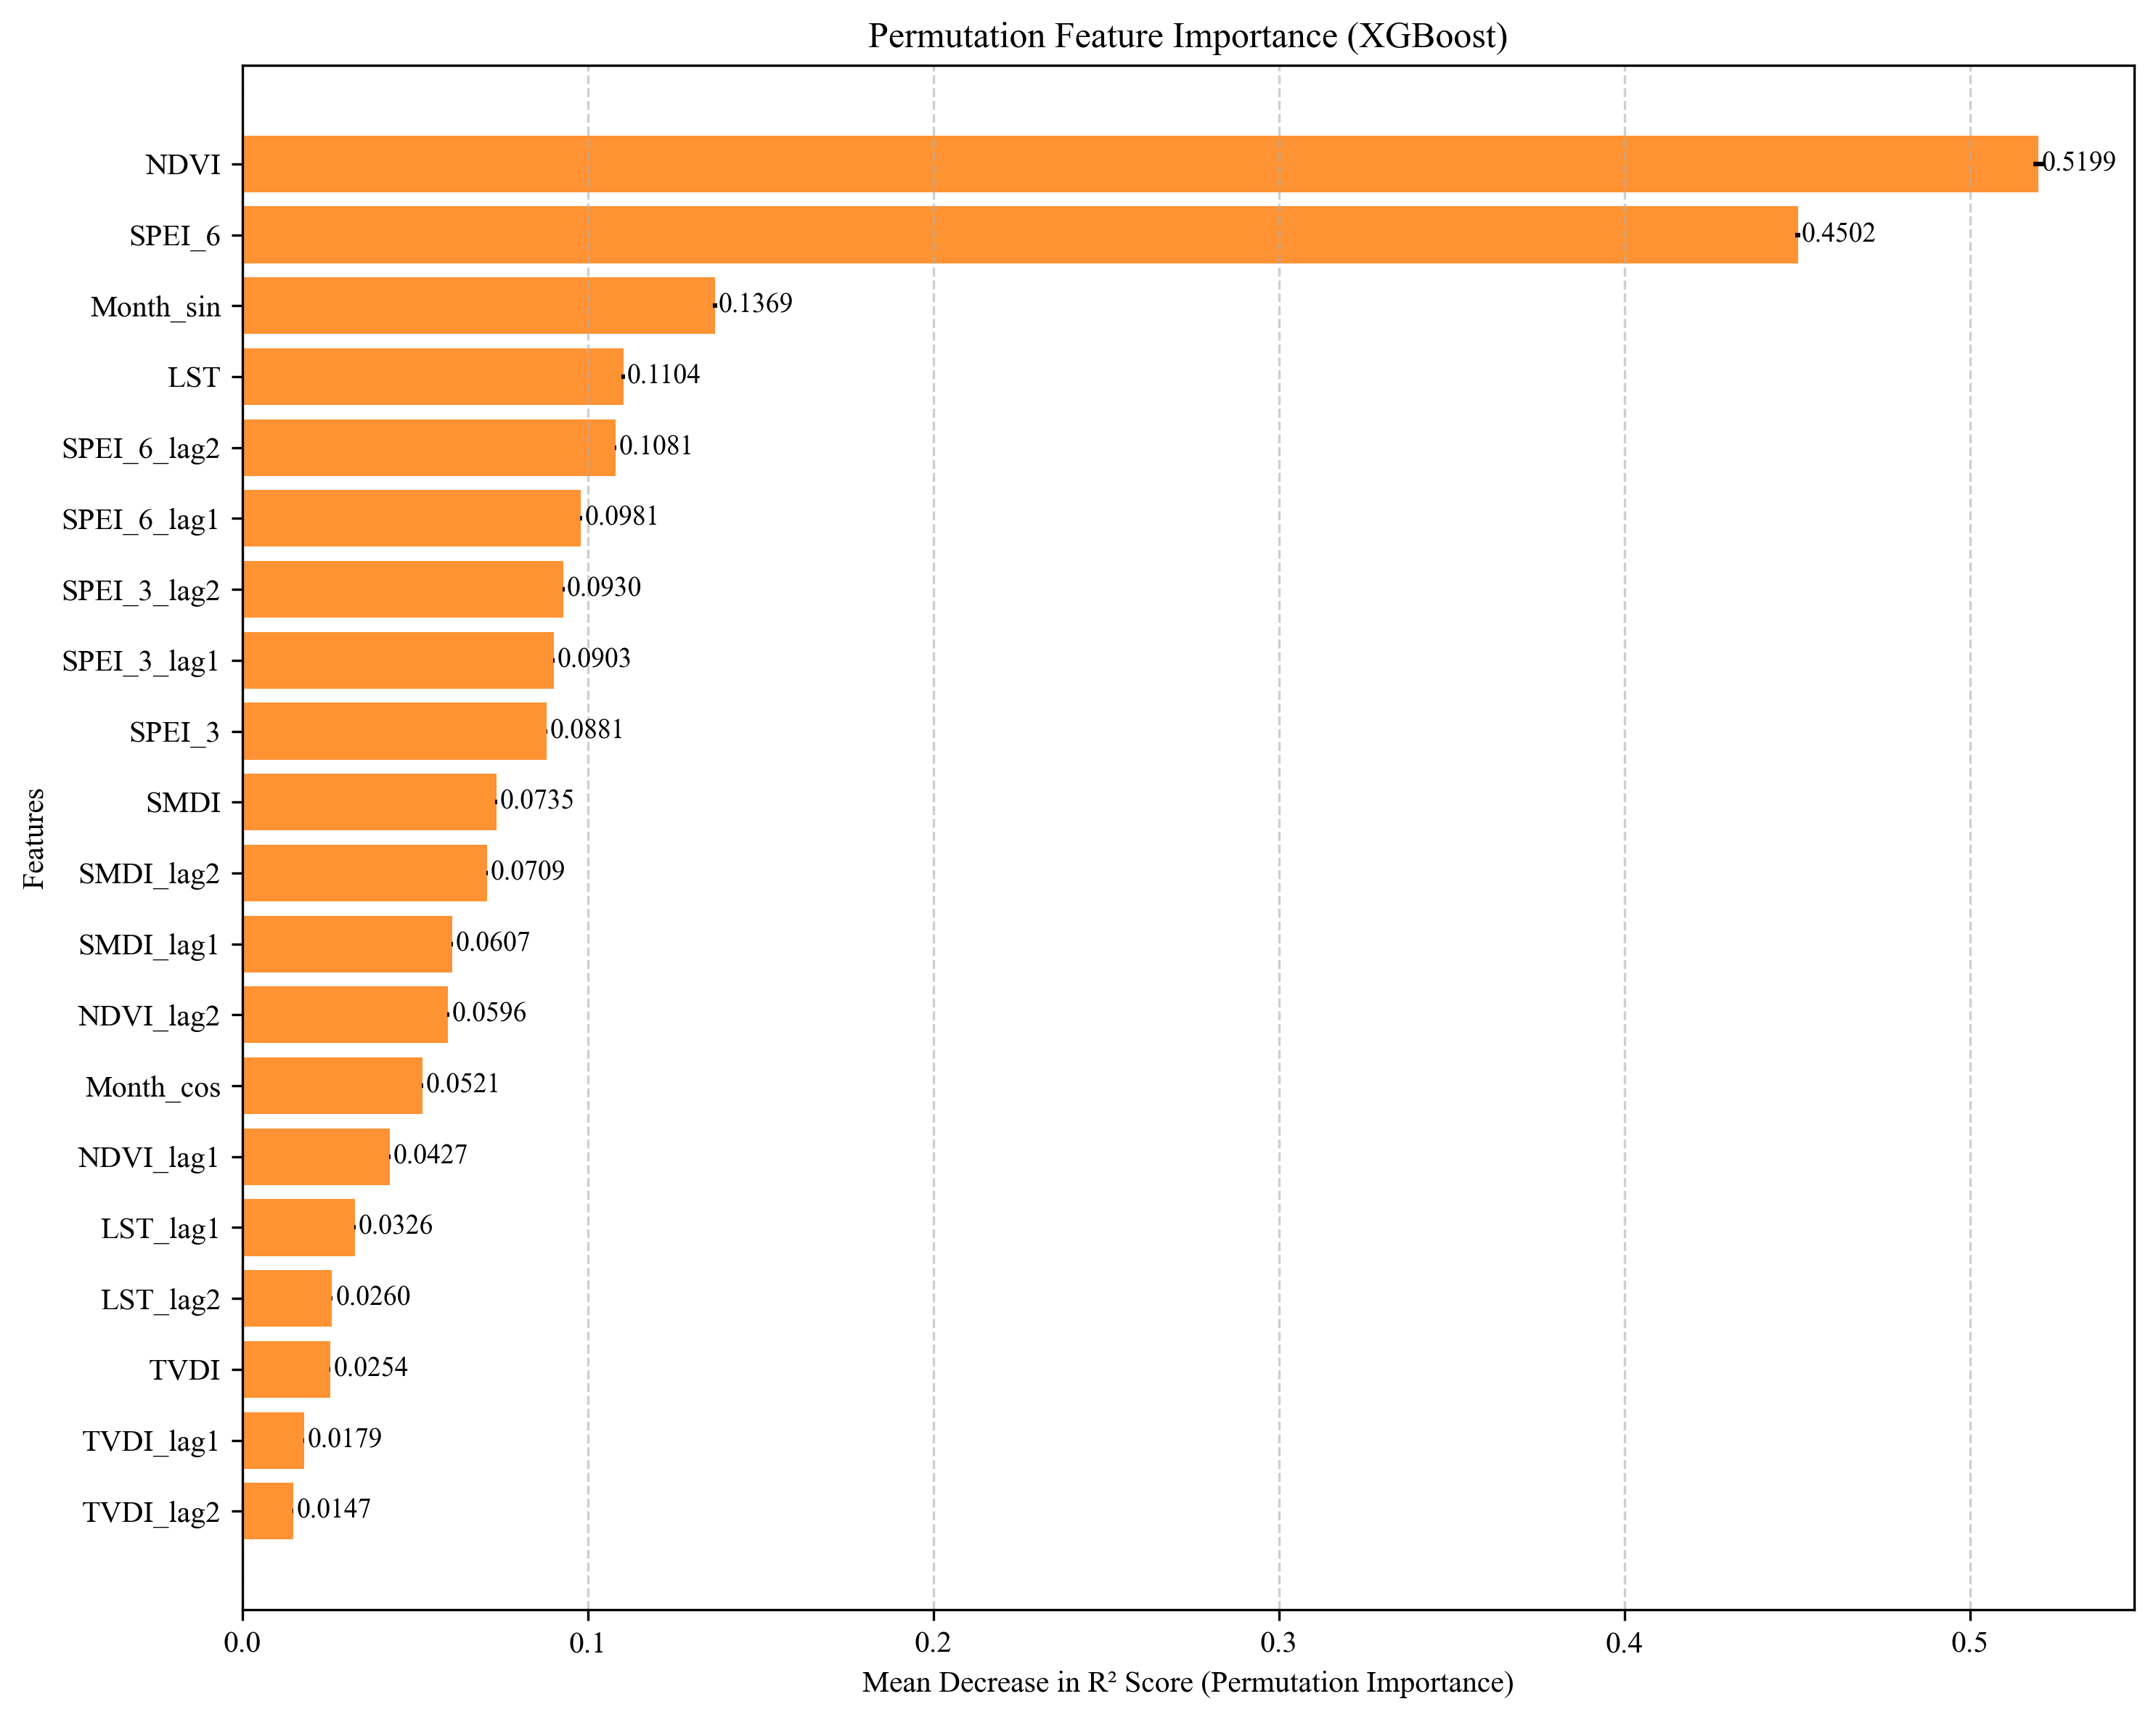


Permutation importance plot and CSV saved in:
E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\shap analysis


In [5]:
# ======================================================================
# PERMUTATION FEATURE IMPORTANCE
# ======================================================================
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import os

print("\nComputing Permutation Feature Importance...")

# Compute permutation importance on test set (more reliable than training set)
perm_importance = permutation_importance(
    xgb_model, 
    X_test, 
    y_test,
    n_repeats=10,           # Number of times to shuffle each feature
    random_state=42,
    n_jobs=-1,
    scoring='r2'            # You can also use 'neg_root_mean_squared_error'
)

# Create DataFrame
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean_Importance': perm_importance.importances_mean,
    'Std_Importance': perm_importance.importances_std
}).sort_values('Mean_Importance', ascending=False)

# Print Top 15
print("\nTop 15 Features by Permutation Importance:")
print(perm_df.head(15)[['Feature', 'Mean_Importance']])

# ======================================================================
# PLOT & SAVE
# ======================================================================
plt.figure(figsize=(10, 8), dpi=300)

top_n = 20
plt.barh(perm_df['Feature'][:top_n], 
         perm_df['Mean_Importance'][:top_n], 
         xerr=perm_df['Std_Importance'][:top_n],
         color='tab:orange', alpha=0.85)

plt.xlabel('Mean Decrease in R² Score (Permutation Importance)')
plt.ylabel('Features')
plt.title('Permutation Feature Importance (XGBoost)')
plt.gca().invert_yaxis()
plt.grid(True, axis='x', linestyle='--', alpha=0.6)

# Add value labels
for i, v in enumerate(perm_df['Mean_Importance'][:top_n]):
    plt.text(v + 0.001, i, f"{v:.4f}", va='center', fontsize=9)

plt.tight_layout()

# Save plot
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\shap analysis"
os.makedirs(output_dir, exist_ok=True)

plt.savefig(os.path.join(output_dir, "Permutation_Feature_Importance.png"), 
            dpi=300, bbox_inches='tight')
plt.show()

# Also save as CSV
perm_df.to_csv(os.path.join(output_dir, "Permutation_Importance.csv"), index=False)
print(f"\nPermutation importance plot and CSV saved in:\n{output_dir}")

In [4]:
"""
XGBoost – Temporal Validation (2016–2020 Unseen)
Excludes: NDVI, TVDI and all their lags
Only outputs: Scatter plot + overall scores
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\lagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Final _Update_Analysis without_TVDI\Spearman_without_tvdi\1"
os.makedirs(output_dir, exist_ok=True)

# Journal style
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300
plt.rcParams["axes.linewidth"] = 1.1
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True

print("=" * 70)
print("XGBoost Temporal Validation (Train ≤2015 | Test 2016–2020)")
print("Excluding: NDVI, TVDI and all their lags")
print("=" * 70)

# ============================================================
# 2. LOAD DATA
# ============================================================
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"File not found:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Original shape: {df.shape}")
print(f"All columns: {list(df.columns)}")

# ============================================================
# 3. FEATURE SELECTION (EXCLUDE NDVI, TVDI + lags)
# ============================================================
# Columns to DROP (besides target and Year)
exclude_cols = [
    "NDVI", "NDVI_lag1", "NDVI_lag2",
    "TVDI", "TVDI_lag1", "TVDI_lag2",
    "VCI",          # target
    "Year"          # used only for split
]

# Keep only the allowed features
feature_cols = [c for c in df.columns if c not in exclude_cols]

print(f"\nFeatures used ({len(feature_cols)}):")
print(feature_cols)

# ============================================================
# 4. TEMPORAL SPLIT
# ============================================================
train_mask = df["Year"] <= 2015
test_mask  = (df["Year"] >= 2016) & (df["Year"] <= 2020)

df_train = df[train_mask].copy()
df_test  = df[test_mask].copy()

print(f"\nTrain samples (≤2015): {len(df_train)}")
print(f"Test samples (2016–2020): {len(df_test)}")

if len(df_train) == 0 or len(df_test) == 0:
    raise ValueError("Train or Test set is empty. Check Year values.")

X_train = df_train[feature_cols]
X_test  = df_test[feature_cols]
y_train_raw = df_train["VCI"].values
y_test_raw  = df_test["VCI"].values

# Scale target (fit ONLY on train)
target_scaler = MinMaxScaler()
y_train = target_scaler.fit_transform(y_train_raw.reshape(-1, 1)).ravel()
y_test  = target_scaler.transform(y_test_raw.reshape(-1, 1)).ravel()

# ============================================================
# 5. XGBoost MODEL
# ============================================================
model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.02,
    max_depth=13,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.0,
    reg_alpha=0.1,
    reg_lambda=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

print("\nTraining XGBoost on ≤2015 data...")
model.fit(X_train, y_train)

# Predictions
y_train_pred_scaled = model.predict(X_train)
y_test_pred_scaled  = model.predict(X_test)

# Inverse transform to original VCI scale
y_train_pred = target_scaler.inverse_transform(y_train_pred_scaled.reshape(-1, 1)).ravel()
y_test_pred  = target_scaler.inverse_transform(y_test_pred_scaled.reshape(-1, 1)).ravel()

# ============================================================
# 6. OVERALL SCORES (Unseen 2016–2020)
# ============================================================
r2   = r2_score(y_test_raw, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test_raw, y_test_pred))
mae  = mean_absolute_error(y_test_raw, y_test_pred)
r, _ = pearsonr(y_test_raw, y_test_pred)

print("\n" + "=" * 70)
print("OVERALL PERFORMANCE ON UNSEEN DATA (2016–2020)")
print("=" * 70)
print(f"R²          : {r2:.4f}")
print(f"RMSE        : {rmse:.4f}")
print(f"MAE         : {mae:.4f}")
print(f"Pearson r   : {r:.4f}")
print("=" * 70)

# ============================================================
# 7. JOURNAL-STYLE SCATTER PLOT
# ============================================================
fig, ax = plt.subplots(figsize=(6.2, 5.8), facecolor="white")

ax.scatter(y_test_raw, y_test_pred,
           c="#1f77b4", s=28, alpha=0.65, edgecolors="none", zorder=3)

# 1:1 line
lims = [
    np.min([y_test_raw.min(), y_test_pred.min()]) - 0.02,
    np.max([y_test_raw.max(), y_test_pred.max()]) + 0.02
]
ax.plot(lims, lims, "k--", linewidth=1.4, label="1:1 line", zorder=2)
ax.set_xlim(lims)
ax.set_ylim(lims)

# Metrics box
textstr = (f"R² = {r2:.3f}\n"
           f"RMSE = {rmse:.3f}\n"
           f"MAE = {mae:.3f}\n"
           f"r = {r:.3f}")
props = dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.92, edgecolor="0.5")
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment="top", bbox=props, linespacing=1.4)

ax.set_xlabel("Observed VCI", fontsize=12)
ax.set_ylabel("Predicted VCI", fontsize=12)
ax.set_title("XGBoost – Unseen Validation (2016–2020)\n(NDVI & TVDI excluded)", 
             fontsize=13, fontweight="bold", pad=10)

ax.legend(loc="lower right", frameon=True, edgecolor="0.6", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.5, zorder=0)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()

scatter_path = os.path.join(output_dir, "XGBoost_Scatter_2016-2020_NoNDVI_NoTVDI.png")
plt.savefig(scatter_path, dpi=600, bbox_inches="tight")
plt.close()

print(f"\nScatter plot saved to:\n{scatter_path}")
print("=" * 70)
print("DONE")

XGBoost Temporal Validation (Train ≤2015 | Test 2016–2020)
Excluding: NDVI, TVDI and all their lags
Original shape: (943957, 24)
All columns: ['Row_Idx', 'Col_Idx', 'Year', 'Month_sin', 'Month_cos', 'LST', 'NDVI', 'SMDI', 'SPEI_3', 'SPEI_6', 'TVDI', 'LST_lag1', 'LST_lag2', 'NDVI_lag1', 'NDVI_lag2', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'TVDI_lag1', 'TVDI_lag2', 'VCI']

Features used (16):
['Row_Idx', 'Col_Idx', 'Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'LST_lag1', 'LST_lag2', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2']

Train samples (≤2015): 943957
Test samples (2016–2020): 0


ValueError: Train or Test set is empty. Check Year values.

In [20]:
import pandas as pd

input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\Csv for ML\ALL_INDICES_GrowingSeason_2001_2020_for_ML.csv"
df = pd.read_csv(input_csv)

print("="*60)
print("Year column info:")
print(df["Year"].dtype)
print("\nUnique years (sorted):")
print(sorted(df["Year"].unique()))
print("\nValue counts:")
print(df["Year"].value_counts().sort_index())
print("\nMin year:", df["Year"].min())
print("Max year:", df["Year"].max())
print("Any NaN in Year?:", df["Year"].isna().sum())
print("="*60)

Year column info:
int64

Unique years (sorted):
[np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]

Value counts:
Year
2001    368788
2002    368788
2003    368788
2004    368788
2005    368788
2006    368788
2007    368788
2008    368788
2009    368788
2010    368788
2011    368788
2012    368788
2013    368788
2014    368788
2015    368788
2016    368788
2017    368788
2018    368788
2019    368788
2020    368788
Name: count, dtype: int64

Min year: 2001
Max year: 2020
Any NaN in Year?: 0


In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio
from collections import Counter

# -------------------------------------------------
# 1. Check shape & valid-pixel count of one LST and one SPEI file
# -------------------------------------------------
lst_path  = r"E:\2_Contribution\Final\Preprocess\LST\LST_2001_04.tif"   # any growing-season month
spei_path = r"E:\2_Contribution\Final\Preprocess\SPEI\SPEI3_2001_04.tif"  # ← change to your real SPEI path

with rasterio.open(lst_path) as src_lst:
    lst = src_lst.read(1).astype(np.float32)
    print("LST shape :", lst.shape)
    print("LST nodata:", src_lst.nodata)
    valid_lst = np.sum(~np.isnan(lst) & (lst != src_lst.nodata if src_lst.nodata else True))
    print("LST valid pixels:", valid_lst)

with rasterio.open(spei_path) as src_spei:
    spei = src_spei.read(1).astype(np.float32)
    print("\nSPEI shape :", spei.shape)
    print("SPEI nodata:", src_spei.nodata)
    valid_spei = np.sum(~np.isnan(spei) & (spei != src_spei.nodata if src_spei.nodata else True))
    print("SPEI valid pixels:", valid_spei)

print("\nDifference in valid pixels:", valid_spei - valid_lst)

# -------------------------------------------------
# 2. Compare the actual (Row, Col) sets from your CSVs
# -------------------------------------------------
lst_csv  = r"E:\2_Contribution\Final\Preprocess\1_ML\LST_GrowingSeason_2001_2020.csv"
spei_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\SPEI3_xxxx.csv"   # ← your SPEI CSV

df_lst  = pd.read_csv(lst_csv,  usecols=["Row_idx", "Col_idx", "Year"])
df_spei = pd.read_csv(spei_csv, usecols=["Row_idx", "Col_idx", "Year"])

# Take only year 2001 for speed
lst_2001  = set(zip(df_lst [df_lst ["Year"]==2001]["Row_idx"],
                    df_lst [df_lst ["Year"]==2001]["Col_idx"]))
spei_2001 = set(zip(df_spei[df_spei["Year"]==2001]["Row_idx"],
                    df_spei[df_spei["Year"]==2001]["Col_idx"]))

only_in_spei = spei_2001 - lst_2001
only_in_lst  = lst_2001  - spei_2001

print(f"\nPixels only in SPEI : {len(only_in_spei)}")
print(f"Pixels only in LST  : {len(only_in_lst)}")

# Optional: save the mismatched locations
pd.DataFrame(list(only_in_spei), columns=["Row_idx","Col_idx"]).to_csv(
    r"E:\2_Contribution\Final\Preprocess\1_ML\pixels_only_in_SPEI.csv", index=False)

In [19]:
import os
import numpy as np
import pandas as pd
import rasterio
from tqdm import tqdm

# ============================================================
# USER SETTINGS
# ============================================================
BASE    = r"E:\2_Contribution\Final\Preprocess"
OUT_DIR = os.path.join(BASE, r"1_ML\Csv for ML")
os.makedirs(OUT_DIR, exist_ok=True)

YEARS  = range(2001, 2021)          # 2001–2020
MONTHS = range(4, 11)               # April → October

# (name, folder, filename pattern)
INDICES = {
    "LST":   (os.path.join(BASE, "LST"),    "LST_{year}_{month:02d}.tif"),
    "VCI":   (os.path.join(BASE, "VCI"),    "VCI_{year}_{month:02d}.tif"),
    "SMDI":  (os.path.join(BASE, "SMDI"),   "SMDI_{year}_{month:02d}.tif"),
    "SPEI3": (os.path.join(BASE, "SPEI_3"), "SPEI_3_{year}_{month:02d}.tif"),
    "SPEI6": (os.path.join(BASE, "SPEI_6"), "SPEI_6_{year}_{month:02d}.tif"),
}

DEFAULT_NODATA = -9999
# ============================================================


def get_valid_mask(tif_path):
    with rasterio.open(tif_path) as src:
        data = src.read(1).astype(np.float32)
        nodata = src.nodata if src.nodata is not None else DEFAULT_NODATA
        mask = (~np.isnan(data)) & (data != nodata)
        return mask, data.shape


def find_common_mask():
    print(">>> Building common valid-pixel mask (intersection of all indices)...")
    common_mask = None
    ref_shape = None

    for name, (folder, pattern) in INDICES.items():
        found = False
        for year in YEARS:
            for month in MONTHS:
                f = os.path.join(folder, pattern.format(year=year, month=month))
                if os.path.exists(f):
                    mask, shape = get_valid_mask(f)
                    if common_mask is None:
                        common_mask = mask.copy()
                        ref_shape = shape
                    else:
                        if shape != ref_shape:
                            raise ValueError(
                                f"Shape mismatch! {name} = {shape}, expected {ref_shape}. "
                                "Please reproject all rasters to the same grid first."
                            )
                        common_mask &= mask
                    print(f"  {name:6s} → {mask.sum():,} valid pixels")
                    found = True
                    break
            if found:
                break
        if not found:
            raise FileNotFoundError(f"No files found for {name}")

    n = common_mask.sum()
    print(f"\n✓ Common pixels (intersection) = {n:,}")
    if n == 0:
        raise RuntimeError("No common valid pixels found!")
    return common_mask


def extract_one_index(name, folder, pattern, common_mask):
    rows, cols = np.where(common_mask)
    dfs = []

    for year in tqdm(YEARS, desc=f"{name:6s}", leave=False):
        for month in MONTHS:
            tif = os.path.join(folder, pattern.format(year=year, month=month))
            if not os.path.exists(tif):
                print(f"  ⚠️ Missing: {os.path.basename(tif)}")
                continue

            with rasterio.open(tif) as src:
                data = src.read(1).astype(np.float32)
                nodata = src.nodata if src.nodata is not None else DEFAULT_NODATA
                data[data == nodata] = np.nan
                values = data[rows, cols]

            df = pd.DataFrame({
                "Row_idx": rows,
                "Col_idx": cols,
                "Year": year,
                "Month": month,
                name: values
            })
            dfs.append(df)

    final = pd.concat(dfs, ignore_index=True)
    final = final.sort_values(["Year", "Month", "Row_idx", "Col_idx"]).reset_index(drop=True)
    return final


# ============================================================
# MAIN
# ============================================================
if __name__ == "__main__":
    # 1. Common mask
    common_mask = find_common_mask()

    # 2. Extract every index with the identical pixel set
    print("\n>>> Extracting all indices...")
    results = {}
    for name, (folder, pattern) in INDICES.items():
        df = extract_one_index(name, folder, pattern, common_mask)
        results[name] = df

        # Save individual CSV
        out_csv = os.path.join(OUT_DIR, f"{name}_GrowingSeason_2001_2020.csv")
        df.to_csv(out_csv, index=False)
        print(f"  ✓ Saved {name:6s} → {out_csv}  ({len(df):,} rows)")

    # 3. Merge into ONE wide table for machine learning
    print("\n>>> Creating combined master CSV for ML...")
    master = results["LST"].copy()          # start with LST
    for name in ["VCI", "SMDI", "SPEI3", "SPEI6"]:
        master = master.merge(
            results[name],
            on=["Row_idx", "Col_idx", "Year", "Month"],
            how="inner"                     # safety – should be identical
        )

    # Final sort
    master = master.sort_values(["Year", "Month", "Row_idx", "Col_idx"]).reset_index(drop=True)

    # Save the master file
    master_path = os.path.join(OUT_DIR, "ALL_INDICES_GrowingSeason_2001_2020_for_ML.csv")
    master.to_csv(master_path, index=False)

    # 4. Verification
    print("\n" + "="*65)
    print("VERIFICATION – Value counts per year (must be identical)")
    print("="*65)
    for name, df in results.items():
        print(f"\n{name}:")
        print(df.groupby("Year").size().to_string())

    print("\n" + "="*65)
    print("MASTER FILE SUMMARY")
    print("="*65)
    print(f"File          : {master_path}")
    print(f"Total rows    : {len(master):,}")
    print(f"Columns       : {list(master.columns)}")
    print(f"Years         : {master['Year'].min()} – {master['Year'].max()}")
    print(f"Months        : {sorted(master['Month'].unique())}")
    print(f"Unique pixels : {master.groupby(['Row_idx','Col_idx']).ngroups:,}")

    # Final sanity check
    ref = results["LST"].groupby("Year").size()
    all_ok = all((df.groupby("Year").size() == ref).all() for df in results.values())
    if all_ok and len(master) == len(results["LST"]):
        print("\n✅ SUCCESS – All indices have identical pixel counts.")
        print("   Master CSV is ready for machine learning.")
    else:
        print("\n❌ Something went wrong with the counts – please check the logs.")

>>> Building common valid-pixel mask (intersection of all indices)...
  LST    → 52,709 valid pixels
  VCI    → 52,988 valid pixels
  SMDI   → 52,994 valid pixels
  SPEI3  → 52,973 valid pixels
  SPEI6  → 52,973 valid pixels

✓ Common pixels (intersection) = 52,684

>>> Extracting all indices...


  ✓ Saved LST    → E:\2_Contribution\Final\Preprocess\1_ML\Csv for ML\LST_GrowingSeason_2001_2020.csv  (7,375,760 rows)


  ✓ Saved VCI    → E:\2_Contribution\Final\Preprocess\1_ML\Csv for ML\VCI_GrowingSeason_2001_2020.csv  (7,375,760 rows)


  ✓ Saved SMDI   → E:\2_Contribution\Final\Preprocess\1_ML\Csv for ML\SMDI_GrowingSeason_2001_2020.csv  (7,375,760 rows)


  ✓ Saved SPEI3  → E:\2_Contribution\Final\Preprocess\1_ML\Csv for ML\SPEI3_GrowingSeason_2001_2020.csv  (7,375,760 rows)


  ✓ Saved SPEI6  → E:\2_Contribution\Final\Preprocess\1_ML\Csv for ML\SPEI6_GrowingSeason_2001_2020.csv  (7,375,760 rows)

>>> Creating combined master CSV for ML...

VERIFICATION – Value counts per year (must be identical)

LST:
Year
2001    368788
2002    368788
2003    368788
2004    368788
2005    368788
2006    368788
2007    368788
2008    368788
2009    368788
2010    368788
2011    368788
2012    368788
2013    368788
2014    368788
2015    368788
2016    368788
2017    368788
2018    368788
2019    368788
2020    368788

VCI:
Year
2001    368788
2002    368788
2003    368788
2004    368788
2005    368788
2006    368788
2007    368788
2008    368788
2009    368788
2010    368788
2011    368788
2012    368788
2013    368788
2014    368788
2015    368788
2016    368788
2017    368788
2018    368788
2019    368788
2020    368788

SMDI:
Year
2001    368788
2002    368788
2003    368788
2004    368788
2005    368788
2006    368788
2007    368788
2008    368788
2009    368788
2010   